# VeriQuery · Part D: the Clarifier
**What this notebook does, top to bottom**

1. Sets up a vast.ai GPU box: installs vLLM, downloads **Qwen3-14B-AWQ**, the **BIRD-INTERACT mini-interact** set (300 tasks, SQLite) and the official BIRD-INTERACT code.
2. Writes the clarifier as a plain Python module (`vq_clarifier.py`). This is the file you hand to A for integration.
3. **M1 check (due 25 Oct):** runs the clarifier on hand-made "stubbed" business questions over a toy shop DB.
4. **BIRD-INTERACT evaluation:** the official two-stage user simulator and the official test cases, run in 6 modes:

| mode | what it is | why you need it |
|---|---|---|
| `detection` | clarifier only, no SQL, no simulator | ask-when-needed and false-ask rates. **Works without ground truth.** |
| `no_clarifier` | SQL written straight from the ambiguous question | the **"without clarifier" ablation** |
| `clarifier` | **ours**: clarifier asks the simulated user, then hands a clean question to the SQL writer | headline result |
| `official_prompt` | official BIRD-INTERACT c-Interact prompt, same model | baseline from the paper's setup |
| `answer_each` | no user: answer each reading and label them | the "no user available" path |
| `oracle` | every labeled ambiguity answered perfectly + hidden knowledge restored | upper bound (how good could a perfect clarifier be) |

5. Metrics, plots, the ambiguity taxonomy, error analysis, and a zip of everything for the report.

**v3 changes:** before submitting, the SQL writer now runs its query on the database (read-only, no answers involved) and fixes it if it errors, up to `SELF_REPAIR` = 2 times, in every mode. v2 lost about half of all tasks to SQL that didn't run. The detection prompt also gets worked examples, so it stops flagging explicit wording. Results go to `results_v3/`.

**v2 changes (after the first dev run):** the clarifier keeps asking until every critical ambiguity it found is settled (v1 stopped after ~1.5 questions); the SQL writer gets SQLite/JSON rules (v1 lost ~half its tasks to `JSON_VALUE` / made-up columns), and so does the official baseline, to keep it fair; the detection prompt treats explicit wording and KB-defined terms as clear and checks *what to return*; the install uses `uv`. v2 results went to `results_v2/`.

**How to run:** edit the CONFIG cell, then *Run All*. Each mode saves after every task and resumes where it stopped. Every LLM call is cached on disk, so reruns are free.

### Rough time and cost (100-task dev subset, Qwen3-14B-AWQ). The timing cell prints real numbers for your box.
| | RTX 4090 (~$0.43–0.55/hr) | RTX 5090 (~$0.60–0.80/hr) |
|---|---|---|
| one-time setup (install + model download) | 15–25 min | 15–25 min |
| `detection` | 5–10 min | 3–6 min |
| `no_clarifier` + `oracle` | 10–20 min | 6–12 min |
| `clarifier` | 25–45 min | 15–30 min |
| `official_prompt` | 20–40 min | 12–25 min |
| `answer_each` | 10–20 min | 6–12 min |
| **all modes, 100 tasks** | **~1.2–2.2 h ≈ $0.6–1.2** | **~0.8–1.4 h ≈ $0.6–1.1** |
| all modes, full 300 | ~3.5–6.5 h ≈ $2–3.5 | ~2.5–4 h ≈ $2–3 |

## Before you run (do #1 today)
1. **Email for ground truth.** Send an email to **bird.bench25@gmail.com** with the subject **`[mini-interact GT&Test Cases]`** (they reply automatically, usually within 30 min). The simulator needs the gold SQL to answer like a real user, and scoring needs the test cases. Upload the `.jsonl` they send to `veriquery_d/data/gt/` on the box. Without it, only the M1 stub tests and the `detection` mode run.
2. **vast.ai instance:** 1× RTX 4090 or 5090, **≥ 60 GB disk**, a *PyTorch / Jupyter* template, and **CUDA ≥ 12.8** in the filter (needed for the 5090). A 24 GB card is enough.
3. **Agree with A:** which LLM the team uses (if it's an API model, set `BACKEND="api"` and you don't need the GPU at all), and the shared-state keys. The interface this notebook assumes is documented in section 9.

In [1]:
# ============================== CONFIG (the only cell you normally edit) ==============================
import os, sys
WORK = os.path.abspath("veriquery_d")                 # everything goes in here
os.makedirs(f"{WORK}/src", exist_ok=True); os.makedirs(f"{WORK}/data/gt", exist_ok=True)

BACKEND = "local"                  # "local" = run vLLM on this GPU | "api" = any OpenAI-compatible API
LOCAL_MODEL = "Qwen/Qwen3-14B-AWQ" # fits a 24 GB card with 32k context. Auto-switches to Qwen3-8B-AWQ on <20 GB cards
MAX_MODEL_LEN = 32768
VLLM_PORT = 8000

API_BASE_URL = "https://api.openai.com/v1"           # used only when BACKEND == "api"
API_KEY = os.environ.get("OPENAI_API_KEY", "")
API_MODEL = "gpt-4o-mini"

# User simulator. None = same model as the system. For the final report, a different/stronger simulator model is
# fairer (the paper uses Claude Haiku / GPT-4o class models). Fill these in if the team has an API key.
SIM_BASE_URL, SIM_API_KEY, SIM_MODEL = None, None, None

HF_TOKEN = os.environ.get("HF_TOKEN")   # only needed if Hugging Face asks you to log in for the dataset
GT_FILE = None                          # None = auto-find a .jsonl in veriquery_d/data/gt/

DEV_N, SEED = 100, 42                   # fixed dev subset, as in the project plan
PATIENCE = 3                            # official default: extra turns beyond #labeled ambiguities
WORKERS = 16                            # parallel tasks (vLLM batches them). 4090: 12-16, 5090: 16-24
GPU_PRICE_PER_HR = 0.50                 # what vast charges you per hour, used for cost estimates
RUN_FULL_300 = False                    # flip to True for the milestone run on all 300 tasks
SELF_REPAIR = 2                         # execute-and-fix rounds before submitting SQL (0 = off, same as v1/v2)
RUN_TAG = "v3"                          # results go to veriquery_d/results_v3 (keeps v1 results separate; change for new experiments)
RES = f"{WORK}/results_{RUN_TAG}"; os.makedirs(RES, exist_ok=True)
print("WORK =", WORK)

WORK = /workspace/veriquery_d


## 1 · Install

In [2]:
import subprocess, shutil
def sh(cmd):          # run a shell command, print the tail of its output
    print("$", cmd); r = subprocess.run(cmd, shell=True, text=True, capture_output=True)
    print((r.stdout or "")[-3000:], (r.stderr or "")[-3000:]); return r
def sh_live(cmd):     # run a shell command and stream its output into the notebook
    print("$", cmd); get_ipython().system(cmd)
PY = sys.executable
pkgs = 'openai huggingface_hub "sqlglot==26.16.4" pandas matplotlib tqdm tabulate'
if BACKEND == "local":
    # uv resolves vLLM + the matching PyTorch in a few minutes (plain pip can get stuck for ages)
    sh_live(f"{PY} -m pip install -q uv")
    sh_live(f"{PY} -m uv pip install --python {PY} vllm --torch-backend=auto {pkgs}")
    # PyTorch templates ship a torchaudio built for an older CUDA, which crashes vLLM. We don't need audio.
    sh_live(f"{PY} -m uv pip uninstall --python {PY} torchaudio || true")
    sh_live(f"{PY} -c 'import vllm, torch; print(\"vllm\", vllm.__version__, \"| torch\", torch.__version__, \"| GPU ok:\", torch.cuda.is_available())'")
else:
    sh_live(f"{PY} -m pip install -q {pkgs}")
sh("nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv")

$ /venv/main/bin/python -m pip install -q uv
$ /venv/main/bin/python -m uv pip install --python /venv/main/bin/python vllm --torch-backend=auto openai huggingface_hub "sqlglot==26.16.4" pandas matplotlib tqdm tabulate
Using Python 3.12.15 environment at: /venv/main
Resolved 207 packages in 1.14s                                       
Prepared 1 package in 59ms                                               
Installed 1 package in 29msu130                             
 + torchaudio==2.11.0+cu130
$ /venv/main/bin/python -m uv pip uninstall --python /venv/main/bin/python torchaudio || true
Using Python 3.12.15 environment at: /venv/main
Uninstalled 1 package in 64ms
 - torchaudio==2.11.0+cu130
$ /venv/main/bin/python -c 'import vllm, torch; print("vllm", vllm.__version__, "| torch", torch.__version__, "| GPU ok:", torch.cuda.is_available())'
vllm 0.32.0 | torch 2.13.0+cu132 | GPU ok: True
$ nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv
name, memory.total [MiB], drive

CompletedProcess(args='nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv', returncode=0, stdout='name, memory.total [MiB], driver_version\nNVIDIA GeForce RTX 4090, 24564 MiB, 590.48.01\n', stderr='')

## 2 · Download the data and the official BIRD-INTERACT code

In [3]:
import glob, zipfile, tarfile
from pathlib import Path
REPO = f"{WORK}/BIRD-Interact"
if not os.path.exists(REPO):
    sh(f"git clone --depth 1 https://github.com/bird-bench/BIRD-Interact.git {REPO}")

from huggingface_hub import snapshot_download
DATA = f"{WORK}/data/mini-interact"
snapshot_download(repo_id="birdsql/mini-interact", repo_type="dataset", local_dir=DATA, token=HF_TOKEN)

# unpack any archives in the dataset
for arc in list(Path(DATA).rglob("*.zip")) + list(Path(DATA).rglob("*.tar.gz")) + list(Path(DATA).rglob("*.tgz")):
    flag = arc.with_suffix(arc.suffix + ".done")
    if flag.exists(): continue
    print("extracting", arc)
    if arc.suffix == ".zip": zipfile.ZipFile(arc).extractall(arc.parent)
    else: tarfile.open(arc).extractall(arc.parent)
    flag.touch()

n_sqlite = len(list(Path(DATA).rglob("*.sqlite")))
print("sqlite DBs found:", n_sqlite, "| task files:", [str(p) for p in Path(DATA).rglob("mini_interact*.jsonl")])
if n_sqlite == 0:
    print("!! No .sqlite files. Open the dataset card (huggingface.co/datasets/birdsql/mini-interact) - the DBs may be a separate "
          "Google Drive download. Put each DB as data/mini-interact/<db>/<db>.sqlite next to <db>_schema.txt and <db>_kb.jsonl.")

$ git clone --depth 1 https://github.com/bird-bench/BIRD-Interact.git /workspace/veriquery_d/BIRD-Interact
 Cloning into '/workspace/veriquery_d/BIRD-Interact'...



Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 139 files:   0%|          | 0/139 [00:00<?, ?it/s]

sqlite DBs found: 54 | task files: ['/workspace/veriquery_d/data/mini-interact/mini_interact.jsonl']


## 3 · The code (written to `veriquery_d/src/`, so you can hand the files to your teammates)

**3a · LLM client:** OpenAI-compatible, disk cache, logs tokens and latency per agent.

In [4]:
%%writefile veriquery_d/src/vq_llm.py
# vq_llm.py - tiny OpenAI-compatible LLM client with a disk cache and token/latency logging.
# Works with a local vLLM server (default) or any OpenAI-compatible API (OpenAI, Together, OpenRouter...).
import hashlib
import json
import re
import sqlite3
import threading
import time
from collections import defaultdict

from openai import OpenAI, BadRequestError


def _strip_think(text):
    # Qwen3 / DeepSeek style reasoning block at the start of a reply
    return re.sub(r"^\s*<think>.*?</think>\s*", "", text, flags=re.S)


class LLM:
    def __init__(self, base_url, api_key, model, cache_path, extra_body=None,
                 default_max_tokens=1024, max_retries=4, name="llm"):
        self.client = OpenAI(base_url=base_url, api_key=api_key or "EMPTY", timeout=900)
        self.model = model
        self.extra_body = extra_body or {}
        self.default_max_tokens = default_max_tokens
        self.max_retries = max_retries
        self.name = name
        self._lock = threading.Lock()
        self._db = sqlite3.connect(cache_path, check_same_thread=False)
        self._db.execute("CREATE TABLE IF NOT EXISTS cache (k TEXT PRIMARY KEY, v TEXT)")
        self._db.commit()
        self.stats = defaultdict(lambda: {"calls": 0, "cached": 0, "errors": 0,
                                          "prompt_tokens": 0, "completion_tokens": 0, "latency_s": 0.0})

    def _key(self, messages, max_tokens, temperature, stop):
        blob = json.dumps([self.model, messages, max_tokens, temperature, stop, self.extra_body],
                          sort_keys=True, ensure_ascii=False)
        return hashlib.sha256(blob.encode()).hexdigest()

    def chat(self, messages, max_tokens=None, temperature=0.0, stop=None, tag="misc", use_cache=True):
        max_tokens = max_tokens or self.default_max_tokens
        k = self._key(messages, max_tokens, temperature, stop)
        if use_cache:
            with self._lock:
                row = self._db.execute("SELECT v FROM cache WHERE k=?", (k,)).fetchone()
            if row:
                with self._lock:
                    self.stats[tag]["cached"] += 1
                return row[0]
        last_err = None
        for attempt in range(self.max_retries):
            t0 = time.time()
            try:
                resp = self.client.chat.completions.create(
                    model=self.model, messages=messages, max_tokens=max_tokens,
                    temperature=temperature, stop=stop,
                    extra_body=self.extra_body or None)
                text = _strip_think(resp.choices[0].message.content or "")
                dt = time.time() - t0
                with self._lock:
                    s = self.stats[tag]
                    s["calls"] += 1
                    s["latency_s"] += dt
                    if resp.usage:
                        s["prompt_tokens"] += resp.usage.prompt_tokens or 0
                        s["completion_tokens"] += resp.usage.completion_tokens or 0
                    if use_cache:
                        self._db.execute("INSERT OR REPLACE INTO cache VALUES (?,?)", (k, text))
                        self._db.commit()
                return text
            except BadRequestError as e:  # e.g. prompt longer than max_model_len -> do not retry
                with self._lock:
                    self.stats[tag]["errors"] += 1
                print(f"[{self.name}] BadRequest ({tag}): {str(e)[:200]}")
                return ""
            except Exception as e:  # network hiccup / server busy -> back off and retry
                last_err = e
                time.sleep(2 * (attempt + 1))
        with self._lock:
            self.stats[tag]["errors"] += 1
        print(f"[{self.name}] failed after retries ({tag}): {str(last_err)[:200]}")
        return ""

    def snapshot(self):
        with self._lock:
            return {k: dict(v) for k, v in self.stats.items()}


def stats_diff(after, before):
    out = {}
    for tag, s in after.items():
        b = before.get(tag, {})
        out[tag] = {k: s[k] - b.get(k, 0) for k in s}
    return out


def extract_json(text):
    """Pull the first JSON object out of an LLM reply (handles ```json fences and chatter)."""
    if not text:
        return None
    t = re.sub(r"```(?:json)?", "", text)
    start = t.find("{")
    while start != -1:
        depth, in_str, esc = 0, False, False
        for i in range(start, len(t)):
            c = t[i]
            if in_str:
                if esc:
                    esc = False
                elif c == "\\":
                    esc = True
                elif c == '"':
                    in_str = False
            elif c == '"':
                in_str = True
            elif c == "{":
                depth += 1
            elif c == "}":
                depth -= 1
                if depth == 0:
                    cand = t[start:i + 1]
                    try:
                        return json.loads(cand)
                    except Exception:
                        try:  # common LLM slip: trailing commas
                            return json.loads(re.sub(r",\s*([}\]])", r"\1", cand))
                        except Exception:
                            break
        start = t.find("{", start + 1)
    return None


def extract_sql(text):
    """Get SQL out of ```sqlite / ```sql blocks, falling back to the first SELECT/WITH statement."""
    if not text:
        return ""
    m = re.findall(r"```(?:sqlite|sql)?\s*(.*?)```", text, flags=re.S | re.I)
    if m:
        cands = [x.strip() for x in m if x.strip()]
        if cands:
            return cands[-1].replace("</t>", "").strip()
    # fenced block opened but never closed
    m = re.search(r"```(?:sqlite|sql)\s*(.*)", text, flags=re.S | re.I)
    if m:
        return m.group(1).replace("</t>", "").strip()
    m = re.search(r"\b(WITH|SELECT)\b.*", text, flags=re.S | re.I)
    return m.group(0).replace("</t>", "").strip() if m else ""

Writing veriquery_d/src/vq_llm.py


**3b · The Clarifier: your component.** Taxonomy → analyze → decide (proceed / ask / answer_each) → multi-turn → `clarifier_node()` for the orchestrator.

In [5]:
%%writefile veriquery_d/src/vq_clarifier.py
# vq_clarifier.py - VeriQuery Part D: the Clarifier agent (v3).
#
# What it does
#   1. analyze()    : find the ambiguous bits in a question (typed, critical vs non-critical),
#                     with readings, a ready-to-ask clarifying question per ambiguity and
#                     1-3 fully-restated interpretations.
#   2. decide()     : proceed / ask / answer_each   (pure Python policy, no LLM call)
#   3. converse()   : ask ONE question at a time and keep going until every critical ambiguity it
#                     found is settled (or the question budget runs out), then hand over a resolved
#                     question + assumptions to the SQL writer.
#   4. clarifier_node(): drop-in function for the orchestrator (A) using the shared state dict.
#
# v3: worked examples in the detection prompt (stops flagging explicit wording as ambiguous).
# v2 changes: (a) no more stopping early - pending critical ambiguities are tracked in code, the LLM only
# says which ones the user's answers already settled; (b) detection prompt: explicit wording / KB-defined
# terms are clear, vague references to KB concepts and unclear "what to return" are ambiguous.
#
# The clarifier never writes SQL. It hands the SQL writer (C) a clear question.
import json
from dataclasses import dataclass, field, asdict
from typing import List, Optional, Callable

from vq_llm import extract_json

# Team taxonomy (from the project plan) + "return_content" (what to return) + one non-critical bucket.
AMBIGUITY_TYPES = {
    "metric_definition": "what a measure/term means or how it is computed (gross vs net revenue, a domain score, "
                         "a business term with no formula or threshold given anywhere)",
    "time_range": "which period (calendar vs fiscal quarter, 'recent', relative to which date, inclusive bounds)",
    "grouping_level": "at what granularity to aggregate or rank (per store vs per region, per month vs per year)",
    "filter": "which rows count (include cancelled? which status? vague thresholds like 'large', 'high', 'active')",
    "entity_reference": "which table/column/entity a word refers to (two plausible columns or tables)",
    "return_content": "what exactly to return (which values/columns, a list vs a count vs a category label)",
    "output_format": "NON-critical: top-k size, ordering, rounding, which extra columns to show",
}
CRITICAL_TYPES = [t for t in AMBIGUITY_TYPES if t != "output_format"]


@dataclass
class Ambiguity:
    span: str
    type: str
    critical: bool
    readings: List[str] = field(default_factory=list)
    why: str = ""
    clarifying_question: str = ""


@dataclass
class Interpretation:
    label: str
    restated_question: str
    assumptions: List[str] = field(default_factory=list)


@dataclass
class Analysis:
    question: str
    ambiguities: List[Ambiguity] = field(default_factory=list)
    interpretations: List[Interpretation] = field(default_factory=list)
    parse_ok: bool = True
    raw: str = ""

    @property
    def critical(self):
        return [a for a in self.ambiguities if a.critical]

    @property
    def is_ambiguous(self):
        return len(self.critical) > 0

    @staticmethod
    def question_for(a):
        if a.clarifying_question:
            return a.clarifying_question
        if a.readings:
            return f'When you say "{a.span}", do you mean ' + " or ".join(a.readings[:3]) + "?"
        return f'What exactly do you mean by "{a.span}"?'

    def first_question(self):
        return self.question_for(self.critical[0]) if self.critical else None

    def to_dict(self):
        d = asdict(self)
        d.pop("raw", None)
        d["is_ambiguous"] = self.is_ambiguous
        return d


@dataclass
class Step:
    action: str                     # "ask" | "done"
    question: str = ""
    about: str = ""                 # span the question is about
    resolved_spans: List[str] = field(default_factory=list)
    resolved_question: str = ""
    assumptions: List[str] = field(default_factory=list)


ANALYZE_PROMPT = """You are the CLARIFIER agent of VeriQuery. Your only job: decide whether the user's question can be answered by ONE well-defined SQL query, or whether it has more than one sensible reading that would give DIFFERENT results. You do NOT write SQL.

Check the question against the database schema and the external knowledge given above, in this order:
1. Domain terms and metrics (e.g. "revenue", "risk level", "high-value", any score, index, rate or category). For each one: is it defined - in the knowledge base, the schema/column names, or the question itself?
   - Not defined anywhere, but it needs a formula, a threshold or a category list -> CRITICAL metric_definition.
   - Only loosely matches a knowledge-base entry (different wording, or it could match more than one entry) -> CRITICAL metric_definition.
   - A knowledge-base entry the question relies on refers to another concept that is NOT defined anywhere -> CRITICAL metric_definition.
   - Named exactly like a knowledge-base entry, or the question spells out the definition -> clear.
2. Time ranges ("last quarter", "recent", "this year"): calendar vs fiscal, relative to which date, inclusive or not. If the question already says which one ("calendar year 2025", an explicit date range), it is clear.
3. Grouping level: per which entity / at what granularity.
4. Filters and thresholds: which rows count ("active", "large", "failed", "problematic"), vague cut-offs.
5. Entity references: a word that could map to more than one table or column.
6. What to return: if it is unclear which values the user wants back (e.g. "analyze", "show the details", "how X affects Y", a count vs a list vs a label) -> CRITICAL return_content.
7. Output format: top-k size, ordering, rounding, extra columns. These are NON-critical: list them with "critical": false; on their own they never make a question ambiguous.

Rules:
- Only report an ambiguity if a reasonable analyst could pick different readings AND they would lead to different query results.
- If the knowledge base or the schema already pins down the meaning, it is NOT ambiguous. Words the user already qualified ("calendar", "gross", "net", explicit dates or numbers) are NOT ambiguous. Do not invent ambiguity for clear questions - over-asking is a failure too.
- List every distinct ambiguity as its own entry (do not merge two terms into one entry).
- "span" must be copied word-for-word from the question.
- Each "clarifying_question" is ONE short plain-English question about ONE ambiguity, that a business user can answer without knowing SQL.
- Allowed types: metric_definition, time_range, grouping_level, filter, entity_reference, return_content, output_format.

Return ONLY a JSON object, no other text:
{
  "ambiguities": [
    {"span": "...", "type": "...", "critical": true, "readings": ["...", "..."], "why": "one sentence", "clarifying_question": "..."}
  ],
  "interpretations": [
    {"label": "A", "restated_question": "the question rewritten so it is fully unambiguous", "assumptions": ["..."]}
  ]
}
- Put critical ambiguities first, most important first. Use an empty list if there are none.
- "interpretations": exactly 1 item if there is no critical ambiguity (the question restated, plus any minor assumptions); otherwise 2 to MAX_K items covering the most plausible combinations of readings, most likely first.

## Short examples (different database, just to show the bar for "ambiguous")
- "What was the average delivery time in calendar year 2024?" (delivery time is a column) -> no critical ambiguity: the year and the calendar are stated.
- "Show weekly net sales per store for March 2025." (the knowledge base defines "net sales") -> no critical ambiguity: the term is defined and the period is explicit.
- "List the top 5 products by units sold last month." -> no critical ambiguity ("top 5", "units sold" and "last month" are explicit enough); at most a non-critical output_format note.
- "Which suppliers are unreliable?" (nothing defines "unreliable") -> CRITICAL metric_definition on "unreliable"; ask e.g. "What makes a supplier unreliable for you - late deliveries, defect rate, or something else, and above what threshold?"
- "Show the risk score and flagged accounts for each branch." (the knowledge base has "Credit Risk Index" and "Fraud Risk Score"; nothing defines "flagged") -> CRITICAL metric_definition on "risk score" (two possible entries) and CRITICAL filter on "flagged accounts" (no rule given).

## User question
QUESTION_HERE"""

NEXT_STEP_PROMPT = """You are the CLARIFIER agent of VeriQuery, talking to the user to remove ambiguity before SQL is written. You do NOT write SQL.

## Original user question
QUESTION_HERE

## Ambiguities you found earlier
AMBS_HERE

## Conversation so far
DIALOGUE_HERE

BUDGET_HERE

Do this:
1. "resolved": list the "span" of every ambiguity above that the user's answers have now settled (copy the spans exactly). An ambiguity is settled only if the answer actually tells you which reading / definition / threshold to use.
2. Decide the next step. The user prefers a question over a wrong guess, so keep asking while any CRITICAL ambiguity is unsettled. Ask ONE short plain-English question about ONE ambiguity - the most important unsettled one, or something new the user's answers revealed. Never repeat a question the user already answered or refused; if they could not answer, assume something sensible.

Return ONLY JSON, either
{"resolved": ["..."], "action": "ask", "about": "span the question is about", "question": "..."}
or
{"resolved": ["..."], "action": "done", "resolved_question": "the original question rewritten with everything the user told you, fully unambiguous", "assumptions": ["anything you had to assume"]}"""


def format_dialogue(dialogue):
    if not dialogue:
        return "(no questions asked yet)"
    return "\n".join(f"Q{i+1} (you): {d['q']}\nA{i+1} (user): {d['a']}" for i, d in enumerate(dialogue))


def _norm(s):
    return " ".join(str(s).lower().split())


class Clarifier:
    def __init__(self, llm, max_interpretations=3, max_tokens=1500):
        self.llm = llm
        self.k = max_interpretations
        self.max_tokens = max_tokens

    # -------- 1. analysis --------
    def analyze(self, question, context_messages):
        prompt = ANALYZE_PROMPT.replace("MAX_K", str(self.k)).replace("QUESTION_HERE", question)
        raw = self.llm.chat(context_messages + [{"role": "user", "content": prompt}],
                            max_tokens=self.max_tokens, tag="clarifier")
        return self._parse_analysis(question, raw)

    def _parse_analysis(self, question, raw):
        j = extract_json(raw)
        if not isinstance(j, dict):
            # unparseable -> behave like "no clarifier" for this question, but remember it failed
            return Analysis(question, [], [Interpretation("A", question, [])], parse_ok=False, raw=raw)
        ambs = []
        for a in j.get("ambiguities", []) or []:
            if not isinstance(a, dict):
                continue
            t = str(a.get("type", "")).strip().lower()
            if t not in AMBIGUITY_TYPES:
                if "metric" in t or "knowledge" in t:
                    t = "metric_definition"
                elif "format" in t or "order" in t or "sort" in t:
                    t = "output_format"
                elif "return" in t or "intent" in t or "output" in t:
                    t = "return_content"
                else:
                    t = "filter"
            crit = bool(a.get("critical", t != "output_format")) and t != "output_format"
            ambs.append(Ambiguity(span=str(a.get("span", "")), type=t, critical=crit,
                                  readings=[str(r) for r in (a.get("readings") or [])],
                                  why=str(a.get("why", "")),
                                  clarifying_question=str(a.get("clarifying_question", ""))))
        ambs.sort(key=lambda a: not a.critical)  # critical first, keep model's order otherwise
        interps = []
        for i, it in enumerate(j.get("interpretations", []) or []):
            if isinstance(it, dict) and it.get("restated_question"):
                interps.append(Interpretation(str(it.get("label", chr(65 + i))), str(it["restated_question"]),
                                              [str(x) for x in (it.get("assumptions") or [])]))
        if not interps:
            interps = [Interpretation("A", question, [])]
        return Analysis(question, ambs, interps[: self.k], parse_ok=True, raw=raw)

    # -------- 2. policy --------
    @staticmethod
    def decide(analysis, user_available):
        if not analysis.is_ambiguous:
            return "proceed"
        return "ask" if user_available else "answer_each"

    # -------- 3. multi-turn --------
    def next_step(self, question, context_messages, analysis, dialogue, turns_left):
        ambs = json.dumps([{"span": a.span, "type": a.type, "critical": a.critical, "readings": a.readings}
                           for a in analysis.ambiguities], ensure_ascii=False, indent=1)
        budget = (f"You can ask at most {turns_left} more question(s)." if turns_left > 0 else
                  'You cannot ask any more questions now: you MUST return "action": "done".')
        prompt = (NEXT_STEP_PROMPT.replace("QUESTION_HERE", question).replace("AMBS_HERE", ambs)
                  .replace("DIALOGUE_HERE", format_dialogue(dialogue)).replace("BUDGET_HERE", budget))
        raw = self.llm.chat(context_messages + [{"role": "user", "content": prompt}],
                            max_tokens=700, tag="clarifier")
        j = extract_json(raw) or {}
        resolved = [str(x) for x in (j.get("resolved") or [])]
        if j.get("action") == "ask" and j.get("question") and turns_left > 0:
            q = str(j["question"]).strip()
            if not any(_norm(q) == _norm(d["q"]) for d in dialogue):  # never repeat yourself
                return Step("ask", question=q, about=str(j.get("about") or ""), resolved_spans=resolved)
        return Step("done", resolved_spans=resolved, resolved_question=str(j.get("resolved_question") or question),
                    assumptions=[str(x) for x in (j.get("assumptions") or [])])

    def converse(self, question, context_messages, ask_user: Callable[[str], str], max_questions=3, analysis=None):
        """Ask until every critical ambiguity is settled or the budget is used.
        ask_user(question) -> answer works with Streamlit, the BIRD-INTERACT simulator, or a human."""
        analysis = analysis or self.analyze(question, context_messages)
        dialogue, step = [], None
        if self.decide(analysis, True) != "ask" or max_questions <= 0:
            return analysis, dialogue, None
        settled, asked_about = set(), set()

        def pending():
            return [a for a in analysis.critical if _norm(a.span) not in settled and _norm(a.span) not in asked_about]

        nxt = analysis.critical[0]
        q, about = Analysis.question_for(nxt), nxt.span
        while q and len(dialogue) < max_questions:
            dialogue.append({"q": q, "a": ask_user(q), "about": about})
            asked_about.add(_norm(about))
            left = max_questions - len(dialogue)
            if left <= 0:
                break
            step = self.next_step(question, context_messages, analysis, dialogue, left)
            settled |= {_norm(s) for s in step.resolved_spans}
            if step.action == "ask":
                q, about = step.question, step.about or step.question
            else:
                p = pending()  # the model wanted to stop, but critical ambiguities it found are still open
                if p:
                    q, about, step = Analysis.question_for(p[0]), p[0].span, None
                else:
                    q = None
        if dialogue and (step is None or step.action != "done"):
            step = self.next_step(question, context_messages, analysis, dialogue, 0)  # forced summary
        return analysis, dialogue, step


# -------- 4. orchestrator hook --------
def clarifier_node(state: dict, clarifier: Clarifier, context_messages, ask_user: Optional[Callable] = None,
                   max_questions=3) -> dict:
    """Shared-state hook. Reads state['question']; writes state['clarification'].

    state['clarification'] = {
        'decision': 'proceed' | 'asked' | 'answer_each',
        'resolved_question': str,          # what the SQL writer should answer (proceed/asked)
        'interpretations': [ {label, restated_question, assumptions} ],   # answer_each -> one SQL per item
        'assumptions': [str], 'dialogue': [{q, a}], 'ambiguities': [...]
    }
    """
    q = state["question"]
    analysis = clarifier.analyze(q, context_messages)
    decision = clarifier.decide(analysis, ask_user is not None)
    out = {"decision": decision, "ambiguities": [asdict(a) for a in analysis.ambiguities],
           "interpretations": [asdict(i) for i in analysis.interpretations], "dialogue": [],
           "resolved_question": analysis.interpretations[0].restated_question,
           "assumptions": analysis.interpretations[0].assumptions}
    if decision == "ask":
        _, dialogue, step = clarifier.converse(q, context_messages, ask_user, max_questions, analysis)
        out.update(decision="asked", dialogue=dialogue,
                   resolved_question=step.resolved_question if step else q,
                   assumptions=step.assumptions if step else [])
    state["clarification"] = out
    return state

Writing veriquery_d/src/vq_clarifier.py


**3c · BIRD-INTERACT harness:** data loading, shared context, the **official** simulator prompts and **official** test-case evaluation (imported from the cloned repo), a stand-in SQL writer (until C's is ready), the 6 modes, and metrics.

In [6]:
%%writefile veriquery_d/src/vq_bird_interact.py
# vq_bird_interact.py - BIRD-INTERACT (mini-interact, SQLite) harness for the VeriQuery clarifier.
# Data loading, context building, the OFFICIAL two-stage user simulator, the OFFICIAL evaluator,
# a stand-in SQL writer, the episode runners for every mode, and the metrics.
import importlib.util
import json
import os
import random
import re
import shutil
import sqlite3
import sys
import tempfile
import threading
import time
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

from vq_llm import extract_sql, stats_diff
from vq_clarifier import Clarifier, format_dialogue


# ----------------------------------------------------------------------------- data
def _as_list(x):
    if x is None or x == "":
        return []
    if isinstance(x, str):
        return [x]
    return list(x)


def _maybe_json(x):
    if isinstance(x, str):
        try:
            return json.loads(x)
        except Exception:
            return x
    return x


def labeled_ambiguities(task):
    """All labeled ambiguities of a task: critical query ambiguities + masked-knowledge ambiguities."""
    out = []
    uqa = _maybe_json(task.get("user_query_ambiguity")) or {}
    crit = uqa.get("critical_ambiguity", []) if isinstance(uqa, dict) else []
    for a in crit or []:
        out.append(_norm_amb(a, "critical"))
    for a in _maybe_json(task.get("knowledge_ambiguity")) or []:
        out.append(_norm_amb(a, "knowledge"))
    return out


def non_critical_ambiguities(task):
    uqa = _maybe_json(task.get("user_query_ambiguity")) or {}
    nc = (uqa.get("non_critical_ambiguity") if isinstance(uqa, dict) else None) or task.get("non_critical_ambiguity") or []
    return [_norm_amb(a, "non_critical") for a in _maybe_json(nc) or []]


def _norm_amb(a, source):
    if not isinstance(a, dict):
        return {"term": str(a), "type": "", "sql_snippet": "", "source": source, "deleted_knowledge": None}
    return {"term": str(a.get("term") or a.get("ambiguity_term") or ""),
            "type": str(a.get("type") or a.get("ambiguity_type") or ""),
            "sql_snippet": str(a.get("sql_snippet") or ""),
            "source": source,
            "deleted_knowledge": a.get("deleted_knowledge")}


def official_max_turn(task, patience=3):
    """Same as the official conv pipeline: #critical + #knowledge ambiguities + patience."""
    uqa = _maybe_json(task.get("user_query_ambiguity")) or {}
    n_crit = len(uqa.get("critical_ambiguity", []) or []) if isinstance(uqa, dict) else 0
    n_know = len(_maybe_json(task.get("knowledge_ambiguity")) or [])
    return n_crit + n_know + patience


class MiniInteract:
    """Finds the task file + per-DB files (sqlite, schema, kb, column meanings) under data_dir."""

    def __init__(self, data_dir):
        self.data_dir = Path(data_dir)
        self.dbs = {}
        self.templates = {}
        for p in sorted(self.data_dir.rglob("*.sqlite")):
            if "tmp" in p.parts:
                continue
            if p.stem.endswith("_template"):   # pristine copy, used by the official evaluator
                self.templates.setdefault(p.stem[: -len("_template")], p)
            else:
                self.dbs.setdefault(p.stem, p)
        cands = sorted(self.data_dir.rglob("mini_interact*.jsonl"), key=lambda p: (("gt" in p.name.lower()), len(str(p))))
        self.task_file = cands[0] if cands else None

    def _side(self, db, suffix):
        p = self.dbs.get(db)
        if p is not None and (p.parent / f"{db}{suffix}").exists():
            return p.parent / f"{db}{suffix}"
        hits = list(self.data_dir.rglob(f"{db}{suffix}"))
        return hits[0] if hits else None

    def db_path(self, db):
        return self.dbs.get(db)

    def eval_source(self, db):
        """Official evaluator copies <db>_template.sqlite for every evaluation; fall back to the main file."""
        return self.templates.get(db) or self.dbs.get(db)

    def schema_text(self, db):
        p = self._side(db, "_schema.txt")
        if p:
            return p.read_text(encoding="utf-8", errors="ignore")
        # fallback: build from sqlite itself
        con = sqlite3.connect(f"file:{self.db_path(db)}?mode=ro", uri=True)
        rows = con.execute("SELECT sql FROM sqlite_master WHERE type='table' AND sql IS NOT NULL").fetchall()
        con.close()
        return "\n\n".join(r[0] for r in rows)

    def kb_entries(self, db):
        p = self._side(db, "_kb.jsonl")
        out = []
        if p:
            for line in p.read_text(encoding="utf-8", errors="ignore").splitlines():
                if line.strip():
                    try:
                        out.append(json.loads(line))
                    except Exception:
                        pass
        return out

    def column_meanings(self, db):
        p = self._side(db, "_column_meaning_base.json")
        if p:
            try:
                return json.loads(p.read_text(encoding="utf-8", errors="ignore"))
            except Exception:
                return {}
        return {}

    def load_tasks(self, gt_path=None, task_file=None):
        tf = Path(task_file) if task_file else self.task_file
        if tf is None:
            raise FileNotFoundError(f"No mini_interact*.jsonl found under {self.data_dir}")
        tasks = [json.loads(l) for l in tf.read_text(encoding="utf-8").splitlines() if l.strip()]
        n_gt = 0
        if gt_path and Path(gt_path).exists():
            gt = {}
            for l in Path(gt_path).read_text(encoding="utf-8").splitlines():
                if l.strip():
                    g = json.loads(l)
                    gt[g.get("instance_id")] = g
            for t in tasks:
                g = gt.get(t.get("instance_id"))
                if g:
                    n_gt += 1
                    for k in ("sol_sql", "external_knowledge", "test_cases"):  # same as official combine_public_with_gt.py
                        if k in g:
                            t[k] = g[k]
                    for k, v in g.items():  # anything else: fill only if missing in the public file
                        if k not in t or t[k] in (None, "", [], {}):
                            t[k] = v
        for t in tasks:
            t["sol_sql"] = _as_list(t.get("sol_sql"))
        return tasks, n_gt


def dev_subset(tasks, n=100, seed=42):
    ids = sorted(t["instance_id"] for t in tasks)
    keep = set(random.Random(seed).sample(ids, min(n, len(ids))))
    return [t for t in tasks if t["instance_id"] in keep]


# ----------------------------------------------------------------------------- context
class ContextBuilder:
    """Builds the shared system message (schema + KB). Same prefix for every agent call on a task,
    so vLLM prefix caching re-uses it across clarifier / writer turns."""

    def __init__(self, data: MiniInteract, max_schema_chars=60000, max_kb_chars=30000,
                 include_column_meanings=False, max_colmean_chars=15000):
        self.data = data
        self.max_schema_chars = max_schema_chars
        self.max_kb_chars = max_kb_chars
        self.include_cm = include_column_meanings
        self.max_cm = max_colmean_chars
        self._schema_cache = {}
        self.truncations = 0

    def schema(self, db):
        if db not in self._schema_cache:
            s = self.data.schema_text(db)
            if len(s) > self.max_schema_chars:
                self.truncations += 1
                s = s[: self.max_schema_chars] + "\n... [schema truncated]"
            self._schema_cache[db] = s
        return self._schema_cache[db]

    def kb_text(self, task, mask=True):
        db = task["selected_database"]
        hidden = set()
        if mask:
            for a in _maybe_json(task.get("knowledge_ambiguity")) or []:
                if isinstance(a, dict) and a.get("deleted_knowledge") is not None:
                    hidden.add(a["deleted_knowledge"])
        lines = [json.dumps(e, ensure_ascii=False) for e in self.data.kb_entries(db) if e.get("id") not in hidden]
        kb = "\n".join(lines)
        if len(kb) > self.max_kb_chars:
            kb = kb[: self.max_kb_chars] + "\n... [knowledge truncated]"
        return kb

    def messages(self, task, mask=True, data_cards=None):
        db = task["selected_database"]
        schema = data_cards if data_cards else self.schema(db)  # B's data cards plug in here
        sys_msg = (f'You are one agent inside VeriQuery, a data analyst assistant. You work on the SQLite database "{db}".\n\n'
                   f"## Database schema (with sample rows)\n{schema}\n\n"
                   f"## External knowledge base (domain definitions, one JSON object per line)\n{self.kb_text(task, mask)}\n")
        if self.include_cm:
            cm = json.dumps(self.data.column_meanings(db), ensure_ascii=False)[: self.max_cm]
            sys_msg += f"\n## Column meanings\n{cm}\n"
        return [{"role": "system", "content": sys_msg}]


# ----------------------------------------------------------------------------- official code
def load_official(repo_dir):
    """Import the official mini-interact prompts, SQL segmenter and evaluation code from the cloned repo."""
    base = Path(repo_dir) / "mini_interact" / "knowledge_based" / "mini_interact_conv"

    def _load(name, path):
        spec = importlib.util.spec_from_file_location(name, path)
        mod = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(mod)
        return mod

    prompts = _load("bi_prompts", base / "prompts" / "prompts.py")
    parser = _load("bi_sql_parser", base / "code" / "sql_parser_sqlite.py")
    eval_dir = str(base / "evaluation")
    if eval_dir not in sys.path:
        sys.path.insert(0, eval_dir)
    import single_instance_eval_sqlite as sie  # noqa: E402  (needs eval_dir on sys.path)
    import logger as bi_logger  # noqa: E402
    return {"prompts": prompts, "segment_sql": parser.segment_sql, "sie": sie, "NullLogger": bi_logger.NullLogger}


# ----------------------------------------------------------------------------- user simulator
def _extract_s(text):
    """Official extract_response(): text between <s> and </s>."""
    cut = text.find("</s>")
    t = text[:cut].strip() if cut != -1 else text
    if "<s>" in t:
        t = t[t.find("<s>"):].replace("<s>", "").strip()
    return t


def parse_action(action_text):
    a = action_text.strip()
    m = re.search(r"\b(labeled|unlabeled|unanswerable)\s*\(\s*(.*?)\s*\)", a, flags=re.S | re.I)
    if not m:
        return "unparsed", ""
    return m.group(1).lower(), m.group(2).strip().strip("\"'")


class UserSimulator:
    """Exact re-implementation of the official two-stage simulator (encoder picks an action, decoder answers)."""

    def __init__(self, llm, official, ctx: ContextBuilder):
        self.llm = llm
        self.enc = official["prompts"].user_simulator_encoder
        self.dec = official["prompts"].user_simulator_decoder
        self.segment_sql = official["segment_sql"]
        self.ctx = ctx

    def _amb_json(self, task):
        return ("user_query_ambiguity: \n" + json.dumps(_maybe_json(task.get("user_query_ambiguity")), indent=4)
                + "\n\nknowledge_ambiguity: \n" + json.dumps(_maybe_json(task.get("knowledge_ambiguity")), indent=4))

    def _segs(self, task):
        out = ""
        for i, s in enumerate(task["sol_sql"]):
            if i > 0:
                out += "\n===\n"
            for clause, text in self.segment_sql(s):
                out += clause + ":\n" + text + "\n\n"
        return out.strip()

    def respond(self, task, clarification_q):
        schema = self.ctx.schema(task["selected_database"])
        amb, segs = self._amb_json(task), self._segs(task)
        p1 = (self.enc.replace("[[clarification_Q]]", clarification_q).replace("[[amb_json]]", amb)
              .replace("[[SQL_Glot]]", segs).replace("[[DB_schema]]", schema))
        enc_out = self.llm.chat([{"role": "user", "content": p1}], max_tokens=700, tag="simulator")
        action = _extract_s(enc_out)
        p2 = (self.dec.replace("[[clarification_Q]]", clarification_q).replace("[[Action]]", action)
              .replace("[[amb_json]]", amb).replace("[[SQL_Glot]]", segs)
              .replace("[[GT_SQL]]", "\n\n".join(task["sol_sql"]).strip())
              .replace("[[DB_schema]]", schema).replace("[[clear_query]]", task.get("query", "") or ""))
        dec_out = self.llm.chat([{"role": "user", "content": p2}], max_tokens=300, tag="simulator")
        a_type, a_arg = parse_action(action)
        return {"action": action, "action_type": a_type, "action_arg": a_arg, "response": _extract_s(dec_out)}


# ----------------------------------------------------------------------------- evaluator
DEFAULT_TC_NO_DISTINCT = ("\ndef test_case(pred_sqls, sol_sqls, db_name, conn):\n    pred_sqls = remove_distinct(pred_sqls)\n"
                          "    sol_sqls = remove_distinct(sol_sqls)\n    result = ex_base(pred_sqls, sol_sqls, db_name, conn)\n"
                          "    assert result == 1, f\"ex_base returned {result} but expected 1.\"\n    return result")
DEFAULT_TC_DISTINCT = ("\ndef test_case(pred_sqls, sol_sqls, db_name, conn):\n    result = ex_base(pred_sqls, sol_sqls, db_name, conn)\n"
                       "    assert result == 1, f\"ex_base returned {result} but expected 1.\"\n    return result")


class Evaluator:
    """Calls the official run_preprocessing / run_evaluation_phase (same test cases, same ex_base),
    with a hard per-instance time limit so a runaway LLM query cannot hang the notebook."""

    def __init__(self, official, data: MiniInteract, timeout_s=60):
        self.sie = official["sie"]
        self.NullLogger = official["NullLogger"]
        self.data = data
        self.timeout_s = timeout_s
        self.lock = threading.Lock()  # official test runner swaps sys.stdout -> run one at a time

    def evaluate(self, task, pred_sql):
        if not task.get("sol_sql"):
            return {"status": "no_gt", "exec_error": False, "error_msg": "no ground truth loaded"}
        if not pred_sql or not pred_sql.strip():
            return {"status": "failed", "exec_error": True, "error_msg": "[exec_err_flg] empty SQL"}
        db = task["selected_database"]
        src = self.data.eval_source(db)
        if src is None:
            return {"status": "failed", "exec_error": True, "error_msg": f"[exec_err_flg] database {db} not found"}
        pre = _as_list(task.get("preprocess_sql"))
        clean = _as_list(task.get("clean_up_sqls") or task.get("clean_up_sql"))
        test_cases = task.get("test_cases") or []
        if not test_cases:  # identical to official wrap_up_sql_sqlite.py
            cond = task.get("conditions") or {}
            test_cases = [DEFAULT_TC_DISTINCT if cond.get("distinct") else DEFAULT_TC_NO_DISTINCT]
        with self.lock:
            # like the official evaluator: every evaluation runs on a fresh throwaway copy of the DB,
            # so an LLM-written DELETE/UPDATE can never damage the real file
            tmpdir = tempfile.mkdtemp()
            db_path = os.path.join(tmpdir, f"{db}.sqlite")
            shutil.copy(src, db_path)
            conn = sqlite3.connect(db_path, timeout=30)
            deadline = time.time() + self.timeout_s
            conn.set_progress_handler(lambda: 1 if time.time() > deadline else 0, 20000)
            try:
                if pre:
                    self.sie.run_preprocessing(pre, db_path, self.NullLogger(), conn)
                exec_err, timeout, assert_err, passed, failed, msg = self.sie.run_evaluation_phase(
                    [pred_sql], task["sol_sql"], db_path, test_cases, self.NullLogger(), conn, False, {})
                ok = not (exec_err or timeout or assert_err)
                err = msg if ok else (("[exec_err_flg] " if (exec_err or timeout) else "") + (msg or "wrong result"))
                return {"status": "success" if ok else "failed", "exec_error": bool(exec_err or timeout),
                        "error_msg": err[:1500]}
            except Exception as e:
                return {"status": "failed", "exec_error": True, "error_msg": f"[exec_err_flg] {e}"[:1500]}
            finally:
                try:
                    conn.close()
                except Exception:
                    pass
                shutil.rmtree(tmpdir, ignore_errors=True)


# ----------------------------------------------------------------------------- SQL writer (stand-in for C)
SQLITE_RULES = """SQLite rules (the database is SQLite, not PostgreSQL/MySQL):
- Use ONLY tables and columns that appear in the schema. Never invent a column name.
- Some columns hold JSON text. If a field you need is not a real column, it is probably a key inside a JSON column
  (check the sample rows): read it with json_extract(column, '$.key') or json_extract(column, '$.key.subkey').
- SQLite has NO JSON_VALUE, JSON_QUERY, ILIKE, DATE_TRUNC, EXTRACT(...), :: casts, or schema.table.column paths.
  Use CAST(x AS REAL), strftime(...), julianday(...), LOWER(x) LIKE ..., and CASE WHEN.
- Integer division truncates in SQLite: write 1.0 * a / b (or CAST(a AS REAL) / b) for ratios.
- Keep the query complete: every CTE and parenthesis closed."""

WRITER_PROMPT = """You are the SQL WRITER agent of VeriQuery. Write ONE SQLite query that answers the user's question.
- Apply definitions and formulas from the knowledge base exactly as written.
- If there is a clarification dialogue, the user's answers override any assumption of yours.
- Return the final query in a single ```sqlite code block and nothing else.

""" + SQLITE_RULES + """

## User question
QUESTION_HERE
EXTRA_HERE"""


class SQLWriter:
    """Minimal stand-in for Part C so the clarifier can be measured on its own.
    Swap in C's writer later: any object with .write(ctx_msgs, question, dialogue, resolved, assumptions) and
    .repair(prev_messages, prev_sql, feedback) works."""

    def __init__(self, llm, max_tokens=2500):
        self.llm = llm
        self.max_tokens = max_tokens

    def _messages(self, ctx_msgs, question, dialogue=None, resolved=None, assumptions=None):
        extra = ""
        if dialogue:
            extra += "\n## Clarification dialogue with the user\n" + format_dialogue(dialogue) + "\n"
        if resolved and resolved.strip() and resolved.strip() != question.strip():
            extra += "\n## Clarified version of the question\n" + resolved + "\n"
        if assumptions:
            extra += "\n## Assumptions to apply\n" + "\n".join(f"- {a}" for a in assumptions) + "\n"
        return ctx_msgs + [{"role": "user", "content": WRITER_PROMPT.replace("QUESTION_HERE", question).replace("EXTRA_HERE", extra)}]

    def write(self, ctx_msgs, question, dialogue=None, resolved=None, assumptions=None):
        msgs = self._messages(ctx_msgs, question, dialogue, resolved, assumptions)
        out = self.llm.chat(msgs, max_tokens=self.max_tokens, tag="writer")
        return extract_sql(out), msgs

    def repair(self, prev_messages, prev_sql, feedback):
        msgs = prev_messages + [{"role": "assistant", "content": f"```sqlite\n{prev_sql}\n```"},
                                {"role": "user", "content": feedback + "\nReturn the corrected query in a single ```sqlite code block."}]
        out = self.llm.chat(msgs, max_tokens=self.max_tokens, tag="writer")
        return extract_sql(out)


def official_debug_feedback(ev):
    """Same wording as the official conv pipeline's debug turn."""
    if "[exec_err_flg]" in ev.get("error_msg", ""):
        return "Your SQL is not executable and raises the following error: " + ev["error_msg"]
    return "Are you sure about your SQL? You have one more chance to update your SQL now."


# ----------------------------------------------------------------------------- pre-submission self-check
def exec_check(db_file, sql, timeout_s=30):
    """Run SQL READ-ONLY on the database (no ground truth involved). Returns an error string, or None if it runs.
    This is what a real SQL agent does before answering (and what Part C's writer is meant to do)."""
    if not sql or not sql.strip():
        return "no SQL query was produced"
    if db_file is None:
        return None
    try:
        conn = sqlite3.connect(f"file:{db_file}?mode=ro", uri=True, timeout=30)
    except Exception as e:
        return None  # can't check -> don't block
    deadline = time.time() + timeout_s
    conn.set_progress_handler(lambda: 1 if time.time() > deadline else 0, 20000)
    try:
        cur = conn.execute(sql)
        cur.fetchmany(5)
        return None
    except sqlite3.OperationalError as e:
        msg = str(e)
        if "interrupted" in msg:
            return f"the query took longer than {timeout_s}s (probably a missing join condition or a huge cross join)"
        return msg
    except Exception as e:
        return str(e)
    finally:
        conn.close()


# ----------------------------------------------------------------------------- episode runners
class Harness:
    def __init__(self, data, ctx, clarifier: Clarifier, writer, simulator, evaluator, official,
                 sys_llm, patience=3, allow_debug=True, official_sqlite_tips=True, self_repair=2):
        self.data, self.ctx, self.clar, self.writer = data, ctx, clarifier, writer
        self.sim, self.ev, self.official, self.sys_llm = simulator, evaluator, official, sys_llm
        self.patience = patience
        self.allow_debug = allow_debug
        self.official_sqlite_tips = official_sqlite_tips
        self.self_repair = self_repair  # max execute-and-fix rounds before submitting (0 = off, like v1/v2)

    def _base(self, task, mode):
        return {"instance_id": task["instance_id"], "db": task["selected_database"], "mode": mode,
                "n_labeled": len(labeled_ambiguities(task)), "max_turn": official_max_turn(task, self.patience)}

    def _self_check(self, task, sql, msgs):
        """Execute-and-fix loop: run the draft SQL on the DB (read-only), feed any error back to the writer."""
        src = self.data.eval_source(task["selected_database"])
        fixes, first_err = 0, None
        for _ in range(self.self_repair):
            err = exec_check(src, sql)
            if not err:
                break
            first_err = first_err or err
            fb = f"I ran your SQL on the database and it failed with this error: {err}\nFix the query."
            new_sql = self.writer.repair(msgs, sql, fb)
            if msgs is not None:
                msgs = msgs + [{"role": "assistant", "content": f"```sqlite\n{sql}\n```"},
                               {"role": "user", "content": fb + "\nReturn the corrected query in a single ```sqlite code block."}]
            sql, fixes = new_sql, fixes + 1
        return sql, msgs, fixes, first_err

    def _finish(self, rec, task, sql, msgs):
        if self.self_repair > 0:
            sql, msgs, fixes, first_err = self._self_check(task, sql, msgs)
            rec.update(self_repairs=fixes, draft_error=(first_err or "")[:200])
        t0 = time.time()
        ev = self.ev.evaluate(task, sql)
        rec.update(sql_first=sql, status_first=ev["status"], err_first=ev["error_msg"][:300])
        rec["reward"] = 1.0 if ev["status"] == "success" else 0.0
        if ev["status"] == "failed" and self.allow_debug and msgs is not None:
            sql2 = self.writer.repair(msgs, sql, official_debug_feedback(ev))
            ev2 = self.ev.evaluate(task, sql2)
            rec.update(sql_debug=sql2, status_debug=ev2["status"])
            if ev2["status"] == "success":
                rec["reward"] = 0.5
        rec["success"] = rec["reward"] > 0
        rec["eval_s"] = round(time.time() - t0, 2)
        return rec

    # (a) ablation: no clarifier at all - SQL straight from the ambiguous question
    def run_no_clarifier(self, task):
        rec = self._base(task, "no_clarifier")
        ctx = self.ctx.messages(task)
        sql, msgs = self.writer.write(ctx, task["amb_user_query"])
        rec.update(questions=[], n_questions=0)
        return self._finish(rec, task, sql, msgs)

    # (b) ours: clarifier asks the simulated user, then hands a resolved question to the writer
    def run_clarifier(self, task):
        rec = self._base(task, "clarifier")
        ctx = self.ctx.messages(task)
        q0 = task["amb_user_query"]
        budget = max(rec["max_turn"] - 1, 0)  # last official turn is reserved for the SQL
        sim_log = []

        def ask_user(q):  # the official simulator plays the user; we keep its verdict for the metrics
            r = self.sim.respond(task, q)
            sim_log.append(r)
            return r["response"]

        analysis, dialogue, step = self.clar.converse(q0, ctx, ask_user, max_questions=budget)
        for d, r in zip(dialogue, sim_log):
            d.update(action=r["action_type"], action_arg=r["action_arg"])
        resolved = step.resolved_question if (step and step.action == "done") else None
        assumptions = step.assumptions if (step and step.action == "done") else None
        sql, msgs = self.writer.write(ctx, q0, dialogue, resolved, assumptions)
        rec.update(flagged=analysis.is_ambiguous, parse_ok=analysis.parse_ok,
                   detected=[{"span": a.span, "type": a.type, "critical": a.critical} for a in analysis.ambiguities],
                   questions=dialogue, n_questions=len(dialogue), resolved_question=resolved)
        return self._finish(rec, task, sql, msgs)

    # (c) baseline: the official BIRD-INTERACT c-Interact prompt (one LLM decides ask-or-SQL itself)
    def run_official_baseline(self, task):
        rec = self._base(task, "official_prompt")
        P = self.official["prompts"]
        db = task["selected_database"]
        max_turn = rec["max_turn"]
        prompt = (P.system_react.replace("[[user_query]]", task["amb_user_query"]).replace("[[DB_name]]", db)
                  .replace("[[max_turn]]", str(max_turn)).replace("[[DB_schema]]", self.ctx.schema(db))
                  .replace("[[external_kg]]", self.ctx.kb_text(task, mask=True)).replace("[[column_meanings]]", "{}"))
        if self.official_sqlite_tips:  # same dialect tips our writer gets, so the comparison is about clarifying, not SQLite
            prompt = prompt.replace("<|The End of DB Schema Information|>", SQLITE_RULES + "\n<|The End of DB Schema Information|>", 1)
        dialogue, sql = [], ""
        for turn in range(1, max_turn + 1):
            out = self.sys_llm.chat([{"role": "user", "content": prompt}], max_tokens=2500, tag="baseline")
            out = out.split("### Turn ")[0]
            # official rule: "</s>" -> question, "</t>" -> final SQL; we also accept a bare ```sql block as SQL
            is_sql = ("</t>" in out) or ("```" in out and "</s>" not in out)
            if is_sql or turn == max_turn:
                sql = extract_sql(out)
                break
            q = _extract_s(out)
            r = self.sim.respond(task, q)
            dialogue.append({"q": q, "a": r["response"], "action": r["action_type"], "action_arg": r["action_arg"]})
            left = max_turn - turn
            if left > 1:
                prompt += (out.strip() + "\n- User: " + r["response"] + f"\n\n### Turn {turn+1} ({left} turns left): \n"
                           '# Format: "<s>[YOUR-ONLY-ONE-QUESTION]]</s>" if you choose to ask for clarification; or '
                           '"<t>```sqlite [YOUR-SQL] ```</t>" if you choose to generate final SQL.\n- You: ')
            else:
                prompt += (out.strip() + "\n- User: " + r["response"] + f"\n\n### Turn {turn+1} (1 turn left): \n"
                           '# It is the final turn. You MUST provide the final SQLite and follow the format: '
                           '"<t>```sqlite [YOUR-SQL] ```</t>"\n- You: <t>')
        rec.update(questions=dialogue, n_questions=len(dialogue))
        # debug turn reuses the generic writer.repair on the baseline's own transcript
        msgs = [{"role": "user", "content": prompt}]
        return self._finish(rec, task, sql, msgs)

    # (d) no user available: answer each interpretation, label them
    def run_answer_each(self, task):
        rec = self._base(task, "answer_each")
        ctx = self.ctx.messages(task)
        analysis = self.clar.analyze(task["amb_user_query"], ctx)
        results = []
        for it in analysis.interpretations:
            sql, wmsgs = self.writer.write(ctx, task["amb_user_query"], None, it.restated_question, it.assumptions)
            if self.self_repair > 0:
                sql, _, _, _ = self._self_check(task, sql, wmsgs)
            ev = self.ev.evaluate(task, sql)
            results.append({"label": it.label, "restated": it.restated_question, "sql": sql, "status": ev["status"]})
        top1 = bool(results) and results[0]["status"] == "success"
        anyk = any(r["status"] == "success" for r in results)
        rec.update(flagged=analysis.is_ambiguous, interpretations=results, k=len(results),
                   top1=top1, any_k=anyk, success=top1, reward=1.0 if top1 else 0.0, n_questions=0, questions=[])
        return rec

    # (e) upper bound: "perfect clarification". Every labeled ambiguity is answered exactly and the hidden
    #     knowledge is restored, so the only thing left is SQL writing. If the public data ever ships the clear
    #     `query`, that is used instead.
    def run_oracle(self, task):
        rec = self._base(task, "oracle")
        ctx = self.ctx.messages(task, mask=False)
        if task.get("query"):
            sql, msgs = self.writer.write(ctx, task["query"])
            rec.update(oracle_kind="clear_query", questions=[], n_questions=0)
        else:
            dialogue = [{"q": 'What exactly do you mean by "%s"?' % l["term"],
                         "a": "It corresponds to this part of the query logic: %s" % l["sql_snippet"]}
                        for l in labeled_ambiguities(task) + non_critical_ambiguities(task) if l["term"]]
            sql, msgs = self.writer.write(ctx, task["amb_user_query"], dialogue)
            rec.update(oracle_kind="perfect_clarification", questions=[], n_questions=0)
        return self._finish(rec, task, sql, msgs)

    # (f) detection only: no simulator, no GT needed
    def run_detection(self, task):
        rec = self._base(task, "detection")
        a = self.clar.analyze(task["amb_user_query"], self.ctx.messages(task))
        rec.update(flagged=a.is_ambiguous, parse_ok=a.parse_ok,
                   detected=[{"span": x.span, "type": x.type, "critical": x.critical, "readings": x.readings}
                             for x in a.ambiguities],
                   labels=labeled_ambiguities(task))
        if task.get("query"):  # clear twin of the same task -> measures asking unnecessarily
            c = self.clar.analyze(task["query"], self.ctx.messages(task, mask=False))
            rec.update(clear_flagged=c.is_ambiguous,
                       clear_detected=[{"span": x.span, "type": x.type} for x in c.critical])
        return rec

    MODES = {"no_clarifier": "run_no_clarifier", "clarifier": "run_clarifier", "official_prompt": "run_official_baseline",
             "answer_each": "run_answer_each", "oracle": "run_oracle", "detection": "run_detection"}

    def run(self, mode, tasks, out_dir, workers=16, resume=True):
        out = Path(out_dir) / f"{mode}.jsonl"
        out.parent.mkdir(parents=True, exist_ok=True)
        done = {}
        if resume and out.exists():
            for l in out.read_text().splitlines():
                if l.strip():
                    r = json.loads(l)
                    done[r["instance_id"]] = r
        todo = [t for t in tasks if t["instance_id"] not in done]
        fn = getattr(self, self.MODES[mode])
        lock = threading.Lock()
        before = self.sys_llm.snapshot()
        sim_before = self.sim.llm.snapshot() if self.sim and self.sim.llm is not self.sys_llm else None
        t0 = time.time()
        try:
            from tqdm.auto import tqdm
        except Exception:
            tqdm = lambda x, **k: x  # noqa: E731

        def _one(t):
            s = time.time()
            try:
                r = fn(t)
            except Exception as e:
                r = {"instance_id": t["instance_id"], "mode": mode, "crash": repr(e)[:500], "success": False, "reward": 0.0}
            r["wall_s"] = round(time.time() - s, 2)
            return r

        with ThreadPoolExecutor(max_workers=workers) as ex, open(out, "a" if resume else "w") as f:
            futs = [ex.submit(_one, t) for t in todo]
            for fu in tqdm(as_completed(futs), total=len(futs), desc=mode):
                r = fu.result()
                with lock:
                    f.write(json.dumps(r, ensure_ascii=False) + "\n")
                    f.flush()
                done[r["instance_id"]] = r
        wall = time.time() - t0
        usage = stats_diff(self.sys_llm.snapshot(), before)
        if sim_before is not None:
            usage.update({f"sim_{k}": v for k, v in stats_diff(self.sim.llm.snapshot(), sim_before).items()})
        ids = {t["instance_id"] for t in tasks}
        recs = [done[i] for i in done if i in ids]
        return recs, {"mode": mode, "n_new": len(todo), "wall_s": round(wall, 1), "usage": usage}


# ----------------------------------------------------------------------------- metrics
def _norm(s):
    return re.sub(r"[^a-z0-9 ]", " ", str(s).lower()).split()


def fuzzy_match(a, b, thr=0.5):
    """Token-overlap match between a detected span and a labeled ambiguity term."""
    ta, tb = set(_norm(a)), set(_norm(b))
    if not ta or not tb:
        return False
    sa, sb = " ".join(_norm(a)), " ".join(_norm(b))
    if sa in sb or sb in sa:
        return True
    return len(ta & tb) / min(len(ta), len(tb)) >= thr


def labeled_hits(task, questions):
    """Which labeled ambiguities did the simulator say were covered (labeled("term") actions)?"""
    labels = labeled_ambiguities(task)
    hit = set()
    for q in questions or []:
        if q.get("action") == "labeled":
            for i, l in enumerate(labels):
                if fuzzy_match(q.get("action_arg", ""), l["term"]):
                    hit.add(i)
    return hit, len(labels)


def summarize_interactive(recs, tasks_by_id):
    n = len(recs)
    if n == 0:
        return {}
    nq = sum(r.get("n_questions", 0) for r in recs)
    acts = {"labeled": 0, "unlabeled": 0, "unanswerable": 0, "unparsed": 0}
    cov = []
    for r in recs:
        for q in r.get("questions", []) or []:
            acts[q.get("action", "unparsed") if q.get("action") in acts else "unparsed"] += 1
        t = tasks_by_id.get(r["instance_id"])
        if t is not None:
            h, tot = labeled_hits(t, r.get("questions"))
            if tot:
                cov.append(len(h) / tot)
    s = {"n": n,
         "success_rate": sum(bool(r.get("success")) for r in recs) / n,
         "normalized_reward": sum(r.get("reward", 0) for r in recs) / n,
         "first_try_sr": sum(r.get("status_first") == "success" for r in recs) / n,
         "avg_questions": nq / n,
         "pct_tasks_asked": sum(r.get("n_questions", 0) > 0 for r in recs) / n,
         "ambiguity_coverage": (sum(cov) / len(cov)) if cov else None,           # asked when needed
         "unnecessary_q_rate": (acts["unanswerable"] / nq) if nq else None,      # asked unnecessarily
         "unlabeled_q_rate": (acts["unlabeled"] / nq) if nq else None,
         "crashes": sum("crash" in r for r in recs),
         "avg_wall_s": sum(r.get("wall_s", 0) for r in recs) / n}
    if any("self_repairs" in r for r in recs):
        s["draft_sql_error_rate"] = sum(bool(r.get("draft_error")) for r in recs) / n      # before self-check
        s["final_sql_error_rate"] = sum("[exec_err_flg]" in (r.get("err_first") or "") for r in recs) / n  # after
        s["avg_self_repairs"] = sum(r.get("self_repairs", 0) for r in recs) / n
    if recs and recs[0].get("mode") == "answer_each":
        s["any_k_sr"] = sum(bool(r.get("any_k")) for r in recs) / n
        s["avg_k"] = sum(r.get("k", 0) for r in recs) / n
    return s


def summarize_detection(recs):
    n = len(recs)
    if n == 0:
        return {}
    term_tot = term_hit = det_crit = det_matched = 0
    for r in recs:
        labels = r.get("labels", [])
        crit = [d for d in r.get("detected", []) if d.get("critical")]
        det_crit += len(crit)
        for l in labels:
            term_tot += 1
            if any(fuzzy_match(d["span"], l["term"]) for d in crit):
                term_hit += 1
        for d in crit:
            if any(fuzzy_match(d["span"], l["term"]) for l in labels):
                det_matched += 1
    clear = [r for r in recs if "clear_flagged" in r]
    s = {"n_ambiguous": n,
         "flag_rate_on_ambiguous (want high)": sum(bool(r.get("flagged")) for r in recs) / n,
         "labeled_term_recall": term_hit / term_tot if term_tot else None,
         "detected_matching_a_label (precision lower bound)": det_matched / det_crit if det_crit else None,
         "avg_critical_detected": det_crit / n,
         "json_parse_fail": sum(not r.get("parse_ok", True) for r in recs)}
    if clear:
        s["n_clear"] = len(clear)
        s["flag_rate_on_clear (want low)"] = sum(bool(r["clear_flagged"]) for r in clear) / len(clear)
        tp = sum(bool(r.get("flagged")) for r in clear)
        fp = sum(bool(r["clear_flagged"]) for r in clear)
        fn = len(clear) - tp
        prec = tp / (tp + fp) if (tp + fp) else 0
        rec_ = tp / (tp + fn) if (tp + fn) else 0
        s["ask_decision_precision"] = prec
        s["ask_decision_recall"] = rec_
        s["ask_decision_f1"] = 2 * prec * rec_ / (prec + rec_) if (prec + rec_) else 0
    return s

Writing veriquery_d/src/vq_bird_interact.py


## 4 · Start the model server

In [7]:
import time, json, urllib.request
def gpu_info():
    try:
        out = subprocess.run("nvidia-smi --query-gpu=name,memory.total --format=csv,noheader,nounits",
                             shell=True, text=True, capture_output=True).stdout.strip().splitlines()[0]
        name, mem = [x.strip() for x in out.split(",")]; return name, int(mem) / 1024
    except Exception: return "none", 0
GPU_NAME, GPU_GB = gpu_info(); print(f"GPU: {GPU_NAME} ({GPU_GB:.0f} GB)")

def server_up(port=VLLM_PORT):
    try: urllib.request.urlopen(f"http://localhost:{port}/v1/models", timeout=3); return True
    except Exception: return False

vllm_proc = None
if BACKEND == "local":
    if GPU_GB and GPU_GB < 20 and "14B" in LOCAL_MODEL:
        LOCAL_MODEL = "Qwen/Qwen3-8B-AWQ"; print("Small GPU -> switching to", LOCAL_MODEL)
    if not server_up():
        log = open(f"{WORK}/vllm.log", "w")
        cmd = [sys.executable, "-m", "vllm.entrypoints.openai.api_server", "--model", LOCAL_MODEL,
               "--served-model-name", "local", "--max-model-len", str(MAX_MODEL_LEN),
               "--gpu-memory-utilization", "0.90", "--enable-prefix-caching", "--max-num-seqs", "32",
               "--port", str(VLLM_PORT)]
        env = dict(os.environ, **({"HF_TOKEN": HF_TOKEN} if HF_TOKEN else {}))
        vllm_proc = subprocess.Popen(cmd, stdout=log, stderr=subprocess.STDOUT, env=env)
        print("starting vLLM (first time downloads ~10 GB, takes 5-15 min). Log:", f"{WORK}/vllm.log")
        t0 = time.time()
        while not server_up():
            if vllm_proc.poll() is not None:
                print(open(f"{WORK}/vllm.log").read()[-4000:]); raise RuntimeError("vLLM exited - see log above")
            if time.time() - t0 > 1800: raise TimeoutError("vLLM did not come up in 30 min")
            time.sleep(10); print(f"  ...waiting {int(time.time()-t0)}s", end="\r")
    print("\nvLLM is up:", LOCAL_MODEL)

GPU: NVIDIA GeForce RTX 4090 (24 GB)
starting vLLM (first time downloads ~10 GB, takes 5-15 min). Log: /workspace/veriquery_d/vllm.log
  ...waiting 50s
vLLM is up: Qwen/Qwen3-14B-AWQ


## 5 · Wire everything together

In [8]:
sys.path.insert(0, f"{WORK}/src")
import importlib, vq_llm, vq_clarifier, vq_bird_interact
for m in (vq_llm, vq_clarifier, vq_bird_interact): importlib.reload(m)
from vq_llm import LLM
from vq_clarifier import Clarifier, clarifier_node
import vq_bird_interact as bi
import pandas as pd

if BACKEND == "local":
    sys_llm = LLM(f"http://localhost:{VLLM_PORT}/v1", "EMPTY", "local", f"{WORK}/llm_cache.sqlite",
                  extra_body={"chat_template_kwargs": {"enable_thinking": False}}, name=LOCAL_MODEL)
    MODEL_TAG = LOCAL_MODEL
else:
    sys_llm = LLM(API_BASE_URL, API_KEY, API_MODEL, f"{WORK}/llm_cache.sqlite", name=API_MODEL)
    MODEL_TAG = API_MODEL
sim_llm = LLM(SIM_BASE_URL, SIM_API_KEY, SIM_MODEL, f"{WORK}/llm_cache_sim.sqlite", name=SIM_MODEL) if SIM_MODEL else sys_llm
SIM_TAG = SIM_MODEL or MODEL_TAG
print("smoke test:", sys_llm.chat([{"role": "user", "content": "Reply with just the word OK."}], max_tokens=10, use_cache=False))

official = bi.load_official(REPO)
data = bi.MiniInteract(DATA)
gt_file = GT_FILE or next(iter(sorted(glob.glob(f"{WORK}/data/gt/*.jsonl"))), None)
tasks, n_gt = data.load_tasks(gt_path=gt_file)
HAS_GT = n_gt > 0 or all(t.get("sol_sql") for t in tasks)
HAS_CLEAR = sum(bool(t.get("query")) for t in tasks)
print(f"tasks: {len(tasks)} | DBs: {len(data.dbs)} | GT merged: {n_gt} (file: {gt_file}) | have clear `query`: {HAS_CLEAR}")
if not HAS_GT:
    print("!! No ground truth yet -> only the stub tests + `detection` mode will run. Email for GT (see top).")

ctx = bi.ContextBuilder(data, max_schema_chars=60000, max_kb_chars=30000)
clar = Clarifier(sys_llm, max_interpretations=3)
writer = bi.SQLWriter(sys_llm)            # <- swap for C's SQL writer at M2 (same .write / .repair interface)
sim = bi.UserSimulator(sim_llm, official, ctx)
ev = bi.Evaluator(official, data, timeout_s=60)
H = bi.Harness(data, ctx, clar, writer, sim, ev, official, sys_llm, patience=PATIENCE, self_repair=SELF_REPAIR)
TB = {t["instance_id"]: t for t in tasks}
dev = bi.dev_subset(tasks, DEV_N, SEED)
RUN_SET = tasks if RUN_FULL_300 else dev
print("dev subset:", len(dev), "| this run uses:", len(RUN_SET))

smoke test: OK
tasks: 300 | DBs: 27 | GT merged: 300 (file: /workspace/veriquery_d/data/gt/mini_interact_GTs_20251112.jsonl) | have clear `query`: 0
dev subset: 100 | this run uses: 100


### 5b · Look at the data (ambiguity counts, context sizes)

In [9]:
rows = []
for t in tasks:
    labs = bi.labeled_ambiguities(t)
    rows.append({"db": t["selected_database"], "n_critical": sum(l["source"] == "critical" for l in labs),
                 "n_knowledge": sum(l["source"] == "knowledge" for l in labs), "max_turn": bi.official_max_turn(t, PATIENCE)})
df_tasks = pd.DataFrame(rows)
display(df_tasks.describe().round(2))
lens = {db: len(ctx.schema(db)) + len("\n".join(json.dumps(e) for e in data.kb_entries(db))) for db in data.dbs}
df_len = pd.DataFrame({"chars": lens}).assign(est_tokens=lambda d: (d.chars / 3.5).astype(int)).sort_values("chars", ascending=False)
display(df_len.head(10))
if df_len.est_tokens.max() > MAX_MODEL_LEN - 3000:
    print("!! some DB contexts are near the context limit - schema is truncated at 60k chars (see ContextBuilder)")
ex = dev[0]
print("\nEXAMPLE", ex["instance_id"], "\nambiguous :", ex["amb_user_query"], "\nclear     :", ex.get("query", "(not public)"))
print("labels    :", json.dumps(bi.labeled_ambiguities(ex), indent=1)[:1500])

,n_critical,n_knowledge,max_turn
count,300.00,300.00,300.00
mean,2.44,0.99,6.43
std,0.89,0.52,1.08
min,1.00,0.00,4.00
25%,2.00,1.00,6.00
50%,2.00,1.00,6.00
75%,3.00,1.00,7.00
max,5.00,4.00,11.00


,chars,est_tokens
exchange_traded_funds,57599,16456
polar,50671,14477
cold_chain_pharma_compliance,49078,14022
organ_transplant,46058,13159
museum,43672,12477
virtual,43601,12457
cybermarket,43158,12330
archeology,41841,11954
hulushows,41096,11741
gaming,40703,11629



EXAMPLE alien_3 
ambiguous : Analyze how lunar interference affects observations by showing the current moon phase, average interference level and the count of problematic events for each observatory, sorted by average interference. 
clear     : (not public)
labels    : [
 {
  "term": "interference level",
  "type": "knowledge_linking_ambiguity",
  "sql_snippet": "AVG((1 - o.LunarDistDeg/180) * (1 - o.AtmosTransparency)) AS avg_lif",
  "source": "critical",
  "deleted_knowledge": null
 },
 {
  "term": "problematic events",
  "type": "knowledge_linking_ambiguity",
  "sql_snippet": "SUM(CASE WHEN (1 - o.LunarDistDeg/180) * (1 - o.AtmosTransparency) > 0.5 THEN 1 ELSE 0 END) as High_Lunar_Interference_Events",
  "source": "critical",
  "deleted_knowledge": null
 },
 {
  "term": "Lunar Interference Factor (LIF)",
  "type": "knowledge_ambiguity",
  "sql_snippet": "AVG((1 - o.LunarDistDeg / 180.0) * (1 - o.AtmosTransparency)) AS avg_lif",
  "source": "knowledge",
  "deleted_knowledge": 9
 }


## 6 · M1 deliverable: clarifier on stubbed inputs
A toy shop DB with a knowledge base that defines *gross/net revenue* and a **fiscal year starting 1 April**, which makes *"revenue"* and *"last quarter"* genuinely ambiguous. 4 ambiguous and 4 clear business questions. Show this at the 25 Oct milestone.

In [10]:
import sqlite3
TOY = f"{WORK}/data/toy_shop.sqlite"
if not os.path.exists(TOY):
    c = sqlite3.connect(TOY); c.executescript("""
    CREATE TABLE customers(customer_id INTEGER PRIMARY KEY, name TEXT, segment TEXT, signup_date TEXT, last_login TEXT);
    CREATE TABLE products(product_id INTEGER PRIMARY KEY, name TEXT, category TEXT);
    CREATE TABLE orders(order_id INTEGER PRIMARY KEY, customer_id INT, order_date TEXT, status TEXT);  -- status: paid|cancelled|refunded
    CREATE TABLE order_items(order_id INT, product_id INT, quantity INT, unit_price REAL, discount REAL);
    CREATE TABLE refunds(order_id INT, amount REAL, refund_date TEXT);
    INSERT INTO customers VALUES (1,'Acme','Enterprise','2023-02-01','2025-06-01'),(2,'Bo','SMB','2024-05-10','2024-11-02');
    INSERT INTO products VALUES (1,'Router','Hardware'),(2,'Support plan','Services');
    INSERT INTO orders VALUES (1,1,'2025-03-01','paid'),(2,2,'2025-05-20','refunded');
    INSERT INTO order_items VALUES (1,1,2,100,10),(2,2,1,50,0);
    INSERT INTO refunds VALUES (2,50,'2025-05-25');"""); c.commit(); c.close()

def toy_context():
    con = sqlite3.connect(TOY)
    schema = "\n".join(r[0] + ";" for r in con.execute("SELECT sql FROM sqlite_master WHERE type='table'"))
    for (tname,) in con.execute("SELECT name FROM sqlite_master WHERE type='table'").fetchall():
        schema += f"\n-- sample {tname}: " + str(con.execute(f"SELECT * FROM {tname} LIMIT 2").fetchall())
    kb = "\n".join(json.dumps(x) for x in [
        {"id": 0, "knowledge": "Gross revenue", "definition": "SUM(quantity*unit_price) over order_items"},
        {"id": 1, "knowledge": "Net revenue", "definition": "gross revenue - SUM(discount) - refunds.amount; excludes cancelled orders"},
        {"id": 2, "knowledge": "Fiscal year", "definition": "The company's fiscal year starts on 1 April (FY2025 = 2025-04-01..2026-03-31)"}])
    return [{"role": "system", "content": f'You are one agent inside VeriQuery, a data analyst assistant. You work on the SQLite database "toy_shop".\n\n## Database schema (with sample rows)\n{schema}\n\n## External knowledge base\n{kb}\n'}]

STUBS = [  # (question, should_flag_as_ambiguous)
    ("Which product category lost the most revenue last quarter?", True),
    ("Who are our top customers?", True),
    ("List the active customers.", True),
    ("What is the average order value?", True),
    ("How many orders were placed on 2025-03-01?", False),
    ("What was the total refund amount in calendar year 2025?", False),
    ("Show monthly gross revenue for 2025 by product category.", False),
    ("How many customers are in the Enterprise segment?", False),
]
TOYCTX = toy_context(); stub_rows = []
for q, gold in STUBS:
    a = clar.analyze(q, TOYCTX)
    stub_rows.append({"question": q, "gold_ambiguous": gold, "flagged": a.is_ambiguous,
                      "decision(user)": Clarifier.decide(a, True), "decision(no user)": Clarifier.decide(a, False),
                      "critical spans": "; ".join(f"{x.span} [{x.type}]" for x in a.critical),
                      "first question": a.first_question() or "", "n_interp": len(a.interpretations)})
df_stub = pd.DataFrame(stub_rows); pd.set_option("display.max_colwidth", 120); display(df_stub)
print(f"stub ask-decision accuracy: {(df_stub.gold_ambiguous == df_stub.flagged).mean():.0%}")

# Full node, both paths: with a (scripted) user, and with no user available
demo_q = STUBS[0][0]
def scripted_user(q):  # a tiny fake user for the demo: answers based on what the question is about
    ql = q.lower()
    if "quarter" in ql or "fiscal" in ql or "calendar" in ql: a = "The fiscal quarter."
    elif "net" in ql or "gross" in ql or "revenue" in ql: a = "Net revenue, please."
    elif "lost" in ql or "loss" in ql or "drop" in ql or "decline" in ql: a = "The biggest drop compared to the quarter before."
    else: a = "No preference, use your best judgement."
    print("  CLARIFIER ASKS:", q, "\n  USER SAYS:    ", a); return a
s1 = clarifier_node({"question": demo_q}, clar, TOYCTX, ask_user=scripted_user, max_questions=3)
print(json.dumps({k: s1["clarification"][k] for k in ["decision", "dialogue", "resolved_question", "assumptions"]}, indent=1))
s2 = clarifier_node({"question": demo_q}, clar, TOYCTX, ask_user=None)
print("\nNO USER ->", s2["clarification"]["decision"]); [print(" ", i["label"], i["restated_question"]) for i in s2["clarification"]["interpretations"]]
df_stub.to_csv(f"{RES}/m1_stub_results.csv", index=False)

,question,gold_ambiguous,flagged,decision(user),decision(no user),critical spans,first question,n_interp
0,Which product category lost the most revenue last quarter?,True,True,ask,answer_each,revenue [metric_definition]; last quarter [time_range],Do you mean gross revenue (before discounts and refunds) or net revenue (after discounts and refunds)?,2
1,Who are our top customers?,True,True,ask,answer_each,top customers [return_content],"What metric should be used to determine the top customers - revenue, number of orders, or number of purchases?",1
2,List the active customers.,True,True,ask,answer_each,active [filter]; customers [entity_reference],"What makes a customer 'active' for you - recent orders, subscription status, or something else?",3
3,What is the average order value?,True,True,ask,answer_each,average order value [metric_definition],"Do you mean the average total value of each order, or the average value per item in each order?",2
4,How many orders were placed on 2025-03-01?,False,False,proceed,proceed,,,1
5,What was the total refund amount in calendar year 2025?,False,True,ask,answer_each,calendar year 2025 [time_range],"Do you mean the calendar year 2025 (January 1 to December 31) or the fiscal year 2025 (April 1, 2025 to March 31, 20...",2
6,Show monthly gross revenue for 2025 by product category.,False,True,ask,answer_each,gross revenue [metric_definition]; 2025 [time_range],Do you mean the sum of quantity multiplied by unit price across all order items for gross revenue?,2
7,How many customers are in the Enterprise segment?,False,False,proceed,proceed,,,1


stub ask-decision accuracy: 75%
  CLARIFIER ASKS: Do you mean gross revenue (before discounts and refunds) or net revenue (after discounts and refunds)? 
  USER SAYS:     Net revenue, please.
  CLARIFIER ASKS: Do you mean the calendar quarter or the fiscal quarter? 
  USER SAYS:     The fiscal quarter.
{
 "decision": "asked",
 "dialogue": [
  {
   "q": "Do you mean gross revenue (before discounts and refunds) or net revenue (after discounts and refunds)?",
   "a": "Net revenue, please.",
   "about": "revenue"
  },
  {
   "q": "Do you mean the calendar quarter or the fiscal quarter?",
   "a": "The fiscal quarter.",
   "about": "last quarter"
  }
 ],
 "resolved_question": "Which product category lost the most net revenue in the fiscal quarter?",
 "assumptions": []
}

NO USER -> answer_each
  A Which product category lost the most gross revenue in the last calendar quarter?
  B Which product category lost the most net revenue in the last fiscal quarter?


## 7 · BIRD-INTERACT evaluation

**7a · Sanity check:** the gold SQL must pass its own test cases. If this isn't ~100%, the DB files or the GT merge are wrong. Fix that before trusting any number.

In [11]:
if HAS_GT:
    chk = [ev.evaluate(t, t["sol_sql"][0]) for t in dev[:25]]
    ok = sum(c["status"] == "success" for c in chk); print(f"gold SQL passes: {ok}/{len(chk)}")
    for t, c in zip(dev[:25], chk):
        if c["status"] != "success": print(" ", t["instance_id"], c["error_msg"][:200])
else:
    print("skip (no GT)")

gold SQL passes: 25/25


**7b · Timing benchmark:** runs `clarifier` (or `detection` without GT) on the first 16 dev tasks at full concurrency, then projects time and $ for each mode. These results are cached and reused by the real run.

In [12]:
bench_mode = "clarifier" if HAS_GT else "detection"
recs, info = H.run(bench_mode, dev[:16], f"{RES}/bench", workers=WORKERS, resume=False)
per_task = info["wall_s"] / max(info["n_new"], 1)
u = info["usage"]; ptok = sum(v["prompt_tokens"] for v in u.values()); ctok = sum(v["completion_tokens"] for v in u.values())
print(f"{bench_mode}: {info['wall_s']}s for {info['n_new']} tasks -> {per_task:.1f}s/task at {WORKERS} workers | "
      f"{ptok/ max(info['n_new'],1):,.0f} prompt + {ctok/ max(info['n_new'],1):,.0f} completion tokens per task")
rel = {"detection": 0.3, "no_clarifier": 0.25, "oracle": 0.25, "answer_each": 0.5, "official_prompt": 0.9, "clarifier": 1.0}
base = per_task / rel[bench_mode]
proj = pd.DataFrame([{"mode": m, "min_per_100": base * r * 100 / 60, "min_per_300": base * r * 300 / 60} for m, r in rel.items()])
proj["usd_per_100"] = proj.min_per_100 / 60 * GPU_PRICE_PER_HR; proj["usd_per_300"] = proj.min_per_300 / 60 * GPU_PRICE_PER_HR
display(proj.round(2)); print("TOTAL all modes: %.0f min / $%.2f (100 tasks), %.0f min / $%.2f (300 tasks)" % (
    proj.min_per_100.sum(), proj.usd_per_100.sum(), proj.min_per_300.sum(), proj.usd_per_300.sum()))

clarifier:   0%|          | 0/16 [00:00<?, ?it/s]

clarifier: 381.6s for 16 tasks -> 23.9s/task at 16 workers | 99,261 prompt + 2,569 completion tokens per task


,mode,min_per_100,min_per_300,usd_per_100,usd_per_300
0,detection,11.92,35.78,0.10,0.30
1,no_clarifier,9.94,29.81,0.08,0.25
2,oracle,9.94,29.81,0.08,0.25
3,answer_each,19.88,59.62,0.17,0.50
4,official_prompt,35.78,107.33,0.30,0.89
5,clarifier,39.75,119.25,0.33,0.99


TOTAL all modes: 127 min / $1.06 (100 tasks), 382 min / $3.18 (300 tasks)


**7c · Detection eval (no GT needed):** does the clarifier flag the ambiguous questions, and find the labeled terms? On clear twins (if the `query` field exists), how often does it ask for no reason?

In [13]:
det_recs, det_info = H.run("detection", RUN_SET, RES, workers=WORKERS)
det_summary = bi.summarize_detection(det_recs)
display(pd.Series(det_summary).to_frame("value"))
if not any("clear_flagged" in r for r in det_recs):
    print("Note: mini-interact has no clear version of each question (every task is ambiguous), so the 'asked when it shouldn't' "
          "side comes from the 4 clear stub questions (section 6) and the simulator's unanswerable() rate in 7d. "
          "For more clear questions later, run clar.analyze on C's BIRD Mini-Dev questions.")

detection:   0%|          | 0/100 [00:00<?, ?it/s]

,value
n_ambiguous,100.000000
flag_rate_on_ambiguous (want high),1.000000
labeled_term_recall,0.699422
detected_matching_a_label (precision lower bound),0.768166
avg_critical_detected,2.890000
json_parse_fail,0.000000


Note: mini-interact has no clear version of each question (every task is ambiguous), so the 'asked when it shouldn't' side comes from the 4 clear stub questions (section 6) and the simulator's unanswerable() rate in 7d. For more clear questions later, run clar.analyze on C's BIRD Mini-Dev questions.


**7d · Interactive eval: all modes** (needs GT). Every mode resumes and is cached, so rerunning a cell is cheap.

In [14]:
MODES = ["no_clarifier", "clarifier", "official_prompt", "answer_each", "oracle"]
ALL, INFO = {}, {}
if HAS_GT:
    for m in MODES:
        ALL[m], INFO[m] = H.run(m, RUN_SET, RES, workers=WORKERS)
    summ = pd.DataFrame({m: bi.summarize_interactive(r, TB) for m, r in ALL.items()}).T
    cost = pd.DataFrame({m: {"wall_min": i["wall_s"] / 60, "usd": i["wall_s"] / 3600 * GPU_PRICE_PER_HR,
                             "prompt_tok": sum(v["prompt_tokens"] for v in i["usage"].values()),
                             "completion_tok": sum(v["completion_tokens"] for v in i["usage"].values())} for m, i in INFO.items()}).T
    summary = summ.join(cost)
    display(summary.round(3))
    summary.to_csv(f"{RES}/summary_{len(RUN_SET)}.csv")
    json.dump({"system_model": MODEL_TAG, "simulator_model": SIM_TAG, "patience": PATIENCE, "n_tasks": len(RUN_SET),
               "seed": SEED, "gpu": GPU_NAME}, open(f"{RES}/run_info.json", "w"), indent=1)
else:
    print("skip (no GT)")

no_clarifier:   0%|          | 0/100 [00:00<?, ?it/s]

clarifier:   0%|          | 0/100 [00:00<?, ?it/s]

official_prompt:   0%|          | 0/100 [00:00<?, ?it/s]

answer_each:   0%|          | 0/100 [00:00<?, ?it/s]

oracle:   0%|          | 0/100 [00:00<?, ?it/s]

,n,success_rate,normalized_reward,first_try_sr,avg_questions,pct_tasks_asked,ambiguity_coverage,unnecessary_q_rate,unlabeled_q_rate,crashes,avg_wall_s,draft_sql_error_rate,final_sql_error_rate,avg_self_repairs,any_k_sr,avg_k,wall_min,usd,prompt_tok,completion_tok
no_clarifier,100.0,0.04,0.035,0.03,0.00,0.0,0.000,NaN,NaN,0.0,150.872,0.47,0.26,0.76,NaN,NaN,17.623,0.147,3213335.0,137138.0
clarifier,100.0,0.16,0.150,0.14,2.47,1.0,0.627,0.077,0.097,0.0,229.598,0.51,0.32,0.90,NaN,NaN,26.255,0.219,6749981.0,131040.0
official_prompt,100.0,0.13,0.125,0.12,1.61,0.9,0.434,0.099,0.118,0.0,257.510,0.50,0.26,0.86,NaN,NaN,27.477,0.229,6463482.0,110713.0
answer_each,100.0,0.02,0.020,0.00,0.00,0.0,0.000,NaN,NaN,0.0,131.568,NaN,NaN,NaN,0.02,1.5,15.657,0.130,3195015.0,112745.0
oracle,100.0,0.35,0.350,0.35,0.00,0.0,0.000,NaN,NaN,0.0,96.760,0.33,0.22,0.59,NaN,NaN,10.542,0.088,2729138.0,102209.0


**How to read the table**
- `normalized_reward`: official BIRD-INTERACT score (1.0 solved first try, 0.5 solved after the one debug turn).
- `ambiguity_coverage`: share of labeled ambiguities the simulator matched to your questions → **"asked when needed"**.
- `unnecessary_q_rate`: share of your questions the simulator rated `unanswerable()` (irrelevant/unneeded) → **"asked unnecessarily"**.
- `no_clarifier` vs `clarifier` → your **with vs without clarifier ablation** (a must-do).
- `answer_each`: `success_rate` = top-1 reading correct; `any_k_sr` = correct reading somewhere in the labeled list.
- `draft_sql_error_rate` vs `final_sql_error_rate`: how much SQL failed to run before vs after the execute-and-fix step.
- `oracle`: what the same SQL writer scores when every ambiguity is answered perfectly. The gap between `clarifier` and `oracle` is how much better the clarifier could still get. The gap between `oracle` and 100% is the SQL writer's (C's) problem.

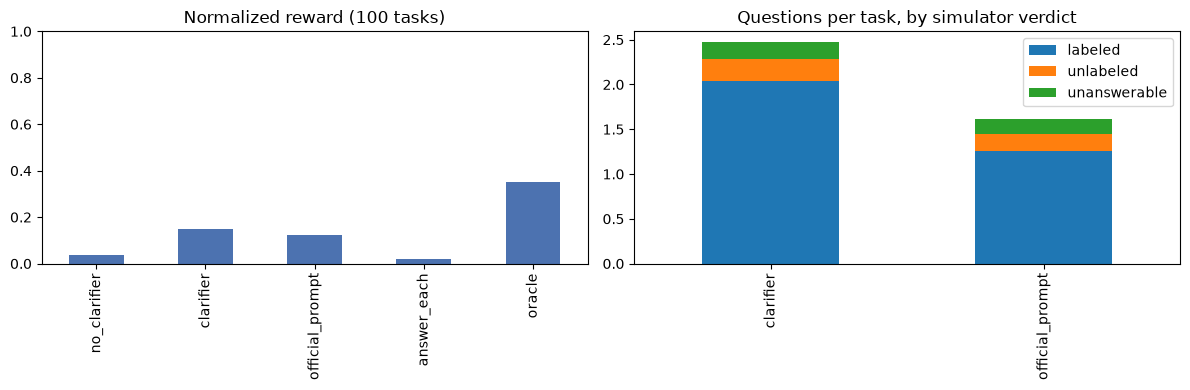

In [15]:
import matplotlib.pyplot as plt
if ALL:
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    summary["normalized_reward"].plot.bar(ax=ax[0], color="#4C72B0"); ax[0].set_title(f"Normalized reward ({len(RUN_SET)} tasks)"); ax[0].set_ylim(0, 1)
    acts = {}
    for m, recs in ALL.items():
        c = {"labeled": 0, "unlabeled": 0, "unanswerable": 0}
        for r in recs:
            for q in r.get("questions", []) or []:
                if q.get("action") in c: c[q["action"]] += 1
        acts[m] = {k: v / len(recs) for k, v in c.items()}
    pd.DataFrame(acts).T.loc[lambda d: d.sum(axis=1) > 0].plot.bar(stacked=True, ax=ax[1]); ax[1].set_title("Questions per task, by simulator verdict")
    plt.tight_layout(); plt.savefig(f"{RES}/fig_modes.png", dpi=150); plt.show()

## 8 · Ambiguity taxonomy and error analysis (stretch item, mostly free once 7d has run)

In [16]:
TAX_PROMPT = """Map each labeled ambiguity from a text-to-SQL benchmark to ONE of these types:
metric_definition, time_range, grouping_level, filter, entity_reference, return_content, output_format.
Question: QUESTION
Ambiguities (term -> SQL snippet):
ITEMS
Return ONLY JSON: {"types": ["...", "..."]} in the same order."""
from vq_llm import extract_json
tax_rows = []
det_by_id = {r["instance_id"]: r for r in det_recs}
clar_by_id = {r["instance_id"]: r for r in ALL.get("clarifier", [])}
for t in RUN_SET:
    labs = bi.labeled_ambiguities(t)
    if not labs: continue
    items = "\n".join(f"{i+1}. '{l['term']}' -> {l['sql_snippet'][:200]}" for i, l in enumerate(labs))
    j = extract_json(sys_llm.chat([{"role": "user", "content": TAX_PROMPT.replace("QUESTION", t["amb_user_query"]).replace("ITEMS", items)}],
                                  max_tokens=300, tag="taxonomy")) or {}
    types = (j.get("types") or []) + ["unknown"] * len(labs)
    d = det_by_id.get(t["instance_id"], {}); c = clar_by_id.get(t["instance_id"])
    hit_ids = bi.labeled_hits(t, c.get("questions"))[0] if c else set()
    for i, l in enumerate(labs):
        tax_rows.append({"instance_id": t["instance_id"], "term": l["term"], "source": l["source"], "bird_type": l["type"],
                         "team_type": types[i], "detected": any(bi.fuzzy_match(x["span"], l["term"]) for x in d.get("detected", []) if x.get("critical")),
                         "asked_about": (i in hit_ids) if c else None, "task_solved": c.get("success") if c else None})
df_tax = pd.DataFrame(tax_rows)
tax_table = df_tax.groupby("team_type").agg(count=("term", "size"), detect_recall=("detected", "mean"),
                                            asked_rate=("asked_about", "mean"), task_success=("task_solved", "mean")).sort_values("count", ascending=False)
display(tax_table.round(2)); display(df_tax.groupby(["source", "bird_type"]).size().rename("count").to_frame())

# failure buckets for the clarifier mode
if clar_by_id:
    def bucket(r):
        if r.get("success"): return "solved"
        if "crash" in r: return "crash"
        t = TB[r["instance_id"]]; h, tot = bi.labeled_hits(t, r.get("questions"))
        if r.get("n_questions", 0) == 0: return "never_asked"
        if len(h) < tot: return "missed_some_ambiguity"
        if "[exec_err_flg]" in (r.get("err_first") or ""): return "sql_not_executable"
        return "asked_everything_but_sql_wrong"   # -> SQL writer (C) problem, not the clarifier
    fails = pd.DataFrame([{**{k: r.get(k) for k in ["instance_id", "db", "n_questions", "sql_first", "err_first"]},
                           "bucket": bucket(r), "question": TB[r["instance_id"]]["amb_user_query"],
                           "dialogue": " || ".join(f"Q: {q['q']} A: {q['a']} [{q.get('action')}]" for q in r.get("questions", []))}
                          for r in ALL["clarifier"]])
    display(fails.bucket.value_counts().to_frame("tasks"))
    fails[fails.bucket != "solved"].to_csv(f"{RES}/clarifier_failures.csv", index=False)

with open(f"{RES}/taxonomy.md", "w") as f:
    f.write("# Ambiguity taxonomy (BIRD-INTERACT mini-interact)\n\n" + tax_table.round(2).to_markdown() + "\n\n## Examples\n")
    for tt, g in df_tax.groupby("team_type"):
        f.write(f"\n### {tt}\n" + "\n".join(f"- `{r.term}` ({r.instance_id})" for r in g.head(4).itertuples()) + "\n")
print("saved taxonomy.md and clarifier_failures.csv")

,count,detect_recall,asked_rate,task_success
team_type,,,,
metric_definition,106,0.71,0.66,0.08
return_content,89,0.80,0.57,0.11
filter,85,0.75,0.65,0.18
grouping_level,28,0.54,0.57,0.25
entity_reference,26,0.50,0.54,0.08
output_format,10,0.20,0.40,0.00
time_range,1,1.00,0.00,1.00
unknown,1,1.00,0.00,0.00


count
source    bird_type                         
critical  intent_ambiguity                34
          knowledge_linking_ambiguity    120
          lexical_ambiguity                8
          schema_linking_ambiguity        53
          semantic_ambiguity              32
          syntactic_ambiguity              2
knowledge knowledge_ambiguity             97

,tasks
bucket,
missed_some_ambiguity,69
solved,16
asked_everything_but_sql_wrong,11
sql_not_executable,4


saved taxonomy.md and clarifier_failures.csv


## 9 · Integration (M2): what you hand to A
`veriquery_d/src/vq_clarifier.py` has no BIRD-INTERACT dependencies. A calls:
```python
state = clarifier_node(state, clarifier, context_messages, ask_user=fn_or_None, max_questions=3)
```
- **reads** `state["question"]`. `context_messages` = system message built from **B's data cards** (`ContextBuilder.messages(task, data_cards=...)`, or any string with schema + knowledge).
- **writes** `state["clarification"]` = `{decision: proceed|asked|answer_each, resolved_question, assumptions, interpretations, dialogue, ambiguities}`.
- **C (SQL writer)** answers `resolved_question` (or one SQL per item in `interpretations` when `decision == "answer_each"`).
- **F (reporter)** prints `assumptions` and labels each interpretation's answer. Streamlit passes `ask_user` as the chat input.
- **E** runs the system-level "minus clarifier" ablation on BIRD Mini-Dev by setting `ask_user=None` and forcing `decision="proceed"`.

When C's writer is ready, replace `writer = bi.SQLWriter(sys_llm)` in section 5 with any object that has the same `.write(ctx_msgs, question, dialogue, resolved, assumptions) -> (sql, msgs)` and `.repair(msgs, sql, feedback) -> sql`, then rerun 7d.

In [17]:
# bundle results + source + cache (re-upload llm_cache*.sqlite to a new box to skip recomputing)
arch = os.path.abspath(f"{WORK}/../veriquery_D_results.zip")
with zipfile.ZipFile(arch, "w", zipfile.ZIP_DEFLATED) as z:
    for sub in [p.name for p in Path(WORK).glob("results*")] + ["src"]:
        for p in Path(WORK, sub).rglob("*"):
            if p.is_file() and "__pycache__" not in p.parts: z.write(p, p.relative_to(WORK))
    for p in Path(WORK).glob("llm_cache*.sqlite"): z.write(p, p.name)
print("download this from the Jupyter file browser:", arch, f"({os.path.getsize(arch)/1e6:.1f} MB)")

download this from the Jupyter file browser: /workspace/veriquery_D_results.zip (1.1 MB)


In [18]:
# stop the model server when you're done (then DESTROY the vast instance so it stops billing)
if vllm_proc is not None:
    vllm_proc.terminate(); print("vLLM stopped")

vLLM stopped
